#Social Media User Analysis
#Exploratory Data Analysis — Instagram Usage Intensity & Psychological Well-being
#EDA Steps:
1. Import Libraries  
2. Load Dataset  
3. Dataset Overview  
4. Data Cleaning & Quality Check  
5. Univariate Analysis  
6. Visualization Gallery (20 Graphs)  
7. Correlation Analysis  
8. Outlier Detection  
9. Key Insights Summary


#Step 1: Import Libraries

In [76]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import pearsonr, linregress
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print(' All libraries imported successfully!')


 All libraries imported successfully!


#Step 2: Load Dataset

In [77]:
file_path = r"C:\Users\HARSHIT PANDEY\OneDrive\Desktop\Internship\Social Media Data-Set.csv"
df = pd.read_csv(file_path)

print(f' Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head()


 Dataset loaded: 99,999 rows × 56 columns


,user_id,app_name,age,gender,country,urban_rural,income_level,employment_status,education_level,relationship_status,has_children,exercise_hours_per_week,sleep_hours_per_night,diet_quality,perceived_stress_score,self_reported_happiness,body_mass_index,blood_pressure_systolic,blood_pressure_diastolic,daily_steps_count,weekly_work_hours,hobbies_count,social_events_per_month,books_read_per_year,volunteer_hours_per_month,travel_frequency_per_year,daily_active_minutes_instagram,sessions_per_day,posts_created_per_week,reels_watched_per_day,stories_viewed_per_day,likes_given_per_day,comments_written_per_day,dms_sent_per_week,dms_received_per_week,ads_viewed_per_day,ads_clicked_per_day,time_on_feed_per_day,time_on_explore_per_day,time_on_messages_per_day,time_on_reels_per_day,followers_count,following_count,uses_premium_features,notification_response_rate,account_creation_year,last_login_date,average_session_length_minutes,content_type_preference,preferred_content_theme,privacy_setting_level,two_factor_auth_enabled,biometric_login_used,linked_accounts_count,subscription_status,user_engagement_score
0,1,Instagram,51,Female,India,Rural,High,Retired,Bachelor,Single,No,7.20,7.70,Good,3,8,20.80,148,86,8107,49.90,3,4,7,4.30,0,5,1,3,42,28,28,5,12,12,4,1,2,1,1,2,374,647,No,0.34,2015,02-11-2025,5.00,Mixed,Tech,Private,Yes,No,0,Free,7.83
1,2,Instagram,64,Female,United Kingdom,Urban,Middle,Full-time employed,Other,Divorced,No,10.90,8.60,Very poor,1,1,23.50,133,84,8059,15.60,0,5,10,4.70,2,74,5,3,78,54,68,15,18,10,11,1,31,19,16,19,2585,3511,No,0.56,2018,22-03-2025,14.80,Photos,Fashion,Public,No,No,3,Free,1.43
2,3,Instagram,41,Female,Canada,Urban,Middle,Student,Bachelor,In a relationship,No,5.00,6.70,Good,4,10,28.60,135,88,7872,31.80,4,5,14,1.50,2,5,1,7,29,26,25,6,12,13,4,0,3,1,1,1,3414,6761,No,0.73,2011,10-08-2025,5.00,Mixed,Other,Public,Yes,Yes,1,Free,9.67
3,4,Instagram,27,Non-binary,South Korea,Urban,Middle,Unemployed,Masters,In a relationship,No,10.60,6.50,Poor,18,1,22.50,105,73,7801,43.40,2,3,13,3.30,4,233,9,5,241,109,132,36,31,32,33,3,108,64,52,64,617,1193,No,0.73,2019,31-03-2025,25.90,Stories,Tech,Private,No,No,1,Free,0.94
4,5,Instagram,55,Male,India,Urban,Upper-middle,Full-time employed,Bachelor,Single,No,7.70,6.80,Average,19,1,28.10,146,90,8005,50.20,2,2,12,4.50,3,184,14,5,146,113,103,36,29,37,20,5,78,55,22,55,1157,1072,Yes,0.65,2017,19-03-2025,13.10,Videos,Food,Public,Yes,No,0,Free,1.03


#Step 3: Dataset Overview

In [78]:
print(' All Columns:')
for i, col in enumerate(df.columns, 1):
    print(f'  {i:2}. {col}')


 All Columns:
   1. user_id
   2. app_name
   3. age
   4. gender
   5. country
   6. urban_rural
   7. income_level
   8. employment_status
   9. education_level
  10. relationship_status
  11. has_children
  12. exercise_hours_per_week
  13. sleep_hours_per_night
  14. diet_quality
  15. perceived_stress_score
  16. self_reported_happiness
  17. body_mass_index
  18. blood_pressure_systolic
  19. blood_pressure_diastolic
  20. daily_steps_count
  21. weekly_work_hours
  22. hobbies_count
  23. social_events_per_month
  24. books_read_per_year
  25. volunteer_hours_per_month
  26. travel_frequency_per_year
  27. daily_active_minutes_instagram
  28. sessions_per_day
  29. posts_created_per_week
  30. reels_watched_per_day
  31. stories_viewed_per_day
  32. likes_given_per_day
  33. comments_written_per_day
  34. dms_sent_per_week
  35. dms_received_per_week
  36. ads_viewed_per_day
  37. ads_clicked_per_day
  38. time_on_feed_per_day
  39. time_on_explore_per_day
  40. time_on_messages

In [79]:
print(' Data Types:')
print(df.dtypes)
print(f'\nNumeric columns  : {df.select_dtypes(include=np.number).shape[1]}')
print(f'Categorical cols : {df.select_dtypes(include="object").shape[1]}')


 Data Types:
user_id                             int64
app_name                           object
age                                 int64
gender                             object
country                            object
urban_rural                        object
income_level                       object
employment_status                  object
education_level                    object
relationship_status                object
has_children                       object
exercise_hours_per_week           float64
sleep_hours_per_night             float64
diet_quality                       object
perceived_stress_score              int64
self_reported_happiness             int64
body_mass_index                   float64
blood_pressure_systolic             int64
blood_pressure_diastolic            int64
daily_steps_count                   int64
weekly_work_hours                 float64
hobbies_count                       int64
social_events_per_month             int64
books_read_per_year  

In [80]:
print(' Summary Statistics:')
df.describe().T


 Summary Statistics:


,count,mean,std,min,25%,50%,75%,max
user_id,99999.00,50000.00,28867.37,1.00,25000.50,50000.00,74999.50,99999.00
age,99999.00,38.98,15.25,13.00,26.00,39.00,52.00,65.00
exercise_hours_per_week,99999.00,7.15,3.99,0.00,4.00,6.60,9.70,23.80
sleep_hours_per_night,99999.00,7.00,1.10,3.00,6.30,7.00,7.70,10.00
perceived_stress_score,99999.00,20.00,11.81,0.00,10.00,20.00,30.00,40.00
self_reported_happiness,99999.00,5.48,2.87,1.00,3.00,5.00,8.00,10.00
body_mass_index,99999.00,24.99,3.97,15.00,22.30,25.00,27.70,43.10
blood_pressure_systolic,99999.00,124.53,20.23,90.00,107.00,125.00,142.00,159.00
blood_pressure_diastolic,99999.00,79.54,11.53,60.00,70.00,80.00,89.00,99.00
daily_steps_count,99999.00,8000.44,89.12,7629.00,7941.00,8000.00,8060.00,8429.00


#Step 4: Data Cleaning & Quality Check

In [81]:
missing = df.isnull().sum()
print(' Missing Values:')
print(missing[missing > 0] if missing.sum() > 0 else ' No missing values found!')


 Missing Values:
 No missing values found!


In [82]:
dupes = df.duplicated().sum()
print(f'Duplicate rows: {dupes}')
if dupes == 0:
    print(' No duplicates!')
else:
    df = df.drop_duplicates()
    print(f'  {dupes} duplicates dropped. New shape: {df.shape}')


Duplicate rows: 0
 No duplicates!


In [83]:
cat_cols = df.select_dtypes(include='object').columns
print(' Unique values in categorical columns:')
for col in cat_cols:
    print(f'  {col:35} → {df[col].nunique()} unique: {df[col].unique().tolist()[:5]}')


 Unique values in categorical columns:
  app_name                            → 1 unique: ['Instagram']
  gender                              → 4 unique: ['Female', 'Non-binary', 'Male', 'Prefer not to say']
  country                             → 10 unique: ['India', 'United Kingdom', 'Canada', 'South Korea', 'United States']
  urban_rural                         → 3 unique: ['Rural', 'Urban', 'Suburban']
  income_level                        → 5 unique: ['High', 'Middle', 'Upper-middle', 'Lower-middle', 'Low']
  employment_status                   → 7 unique: ['Retired', 'Full-time employed', 'Student', 'Unemployed', 'Freelancer']
  education_level                     → 8 unique: ['Bachelor', 'Other', 'Masters', 'High school', 'Some college']
  relationship_status                 → 5 unique: ['Single', 'Divorced', 'In a relationship', 'Married', 'Widowed']
  has_children                        → 2 unique: ['No', 'Yes']
  diet_quality                        → 5 unique: ['Good', 'Very p

In [84]:
key_numeric = ['age','daily_active_minutes_instagram','sessions_per_day',
               'perceived_stress_score','self_reported_happiness',
               'sleep_hours_per_night','exercise_hours_per_week','reels_watched_per_day']
print(f'{"Column":<40} {"Min":>8} {"Max":>8} {"Mean":>8} {"Std":>8}')
print('-' * 70)
for col in key_numeric:
    print(f'{col:<40} {df[col].min():>8.1f} {df[col].max():>8.1f} {df[col].mean():>8.2f} {df[col].std():>8.2f}')


Column                                        Min      Max     Mean      Std
----------------------------------------------------------------------
age                                          13.0     65.0    38.98    15.25
daily_active_minutes_instagram                5.0    561.0   188.70   110.07
sessions_per_day                              1.0     50.0    10.38     7.96
perceived_stress_score                        0.0     40.0    20.00    11.81
self_reported_happiness                       1.0     10.0     5.48     2.87
sleep_hours_per_night                         3.0     10.0     7.00     1.10
exercise_hours_per_week                       0.0     23.8     7.15     3.99
reels_watched_per_day                        21.0    300.0   175.77    76.25


In [85]:
# Derived columns + all shared variables used across all graphs
df['usage_bucket'] = pd.cut(df['daily_active_minutes_instagram'],
    bins=[0,60,120,180,240,300,600],
    labels=['0–60','61–120','121–180','181–240','241–300','300+'])

df['stress_group'] = pd.cut(df['perceived_stress_score'],
    bins=[-1,10,20,30,40],
    labels=['Low (0–10)','Moderate (11–20)','High (21–30)','Very High (31–40)'])

df['age_group'] = pd.cut(df['age'], bins=[12,18,25,35,45,55,65],
    labels=['13–18','19–25','26–35','36–45','46–55','56–65'])

df['last_login_date'] = pd.to_datetime(df['last_login_date'], dayfirst=True, errors='coerce')
df['login_month']     = df['last_login_date'].dt.month
df['login_day_name']  = df['last_login_date'].dt.day_name()

sample   = df.sample(2000, random_state=42)
num_cols = df.select_dtypes(include=np.number).columns.drop('user_id').tolist()

country_colors = {
    'United States':'#E63946', 'India':'#F77F00', 'Brazil':'#4361EE',
    'United Kingdom':'#7209B7', 'Canada':'#06D6A0', 'Other':'#4CC9F0',
    'South Korea':'#F72585', 'Australia':'#FCAF45', 'Germany':'#3A0CA3', 'Japan':'#2DC653'
}
country_order = ['United States','India','Brazil','United Kingdom','Canada',
                 'Australia','South Korea','Germany','Japan','Other']
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

x_line = np.linspace(0, 600, 200)

print('✅ All variables ready:')
print('   usage_bucket, stress_group, age_group, sample, num_cols')
print('   country_colors, country_order, day_order, x_line')
print('   last_login_date, login_month, login_day_name')


 Derived columns ready: usage_bucket, stress_group, age_group
 sample (2000 rows) and num_cols ready for use


#Step 5: Univariate Analysis
#5.1 — Age Distribution

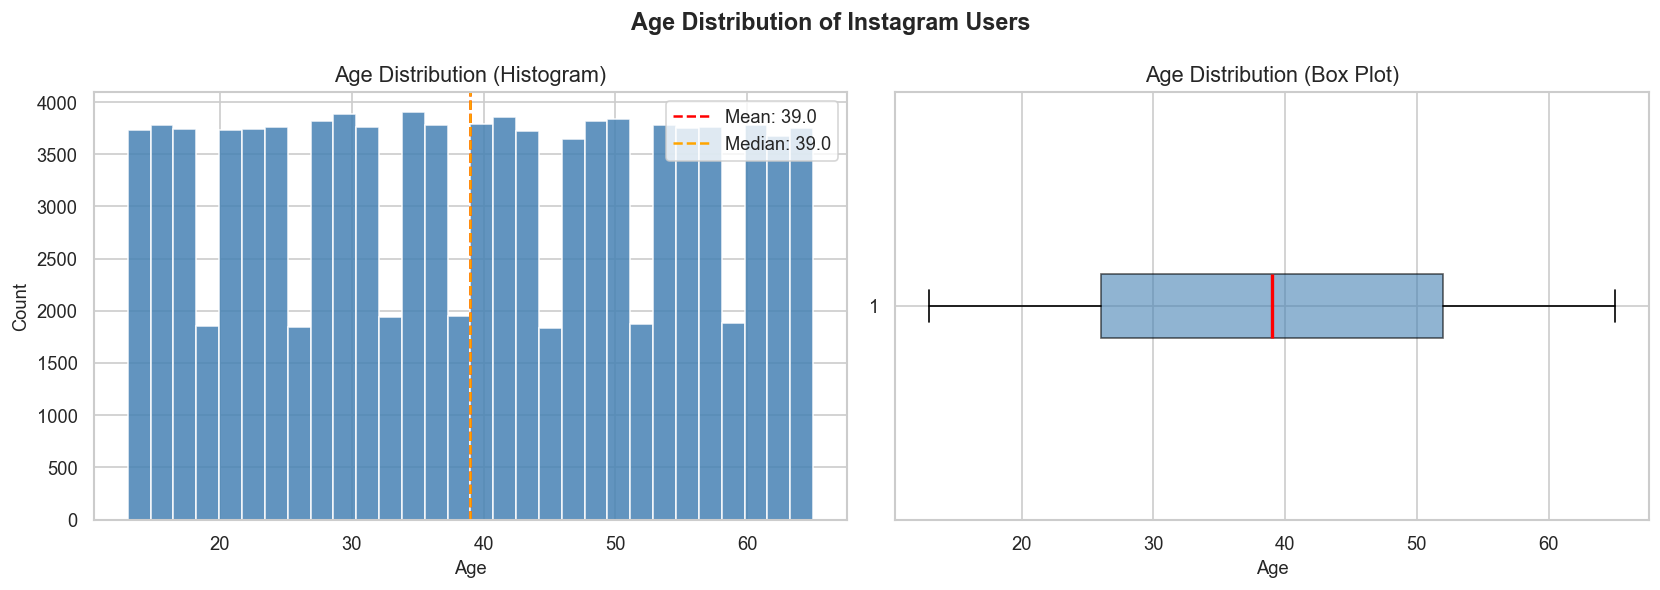

Skewness: 0.003 | Kurtosis: -1.194


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['age'], bins=30, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].axvline(df['age'].mean(),   color='red',    linestyle='--', lw=1.5, label=f"Mean: {df['age'].mean():.1f}")
axes[0].axvline(df['age'].median(), color='orange', linestyle='--', lw=1.5, label=f"Median: {df['age'].median():.1f}")
axes[0].set_title('Age Distribution (Histogram)')
axes[0].set_xlabel('Age'); axes[0].set_ylabel('Count'); axes[0].legend()

axes[1].boxplot(df['age'], vert=False, patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                medianprops=dict(color='red', lw=2))
axes[1].set_title('Age Distribution (Box Plot)'); axes[1].set_xlabel('Age')

plt.suptitle('Age Distribution of Instagram Users', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()
print(f'Skewness: {df["age"].skew():.3f} | Kurtosis: {df["age"].kurtosis():.3f}')


#5.2 — Gender & Country Distribution

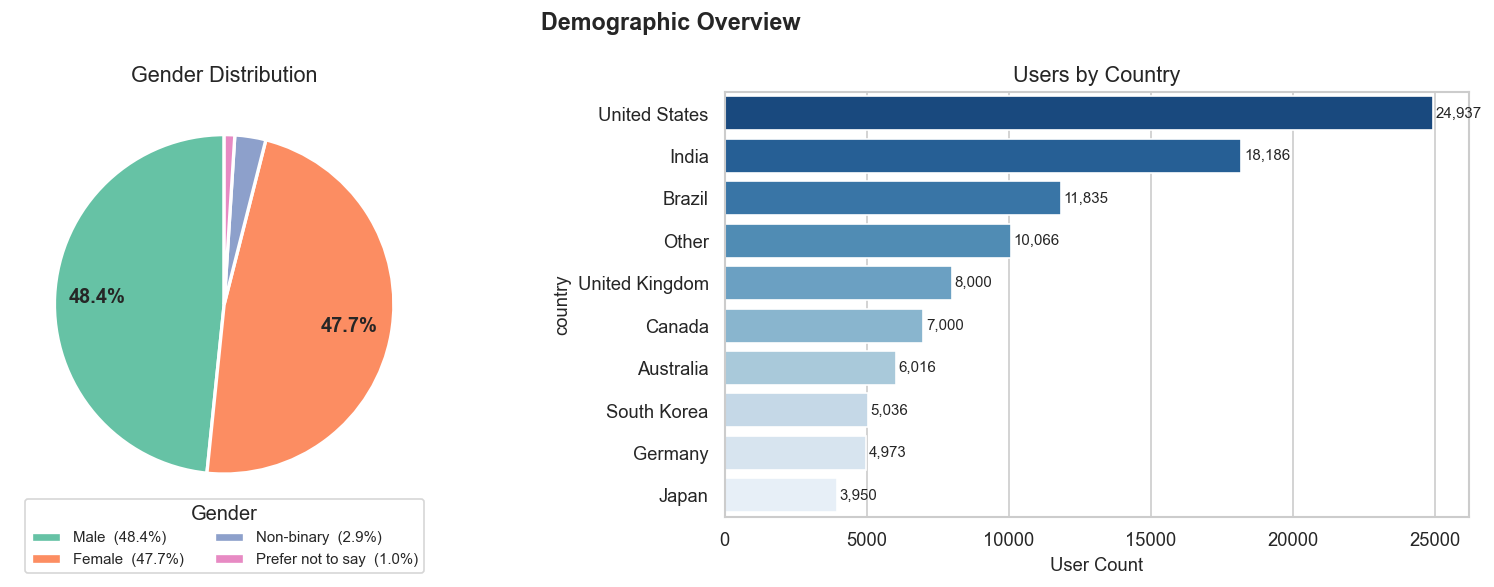

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

g_counts = df['gender'].value_counts()
wedges, texts, autotexts = axes[0].pie(
    g_counts,
    labels=None,
    autopct=lambda pct: f'{pct:.1f}%' if pct > 5 else '',
    pctdistance=0.75,
    colors=sns.color_palette('Set2', len(g_counts)),
    startangle=90,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for at in autotexts:
    at.set_fontsize(12)
    at.set_fontweight('bold')

legend_labels = [f'{label}  ({val/g_counts.sum()*100:.1f}%)' for label, val in zip(g_counts.index, g_counts.values)]
axes[0].legend(wedges, legend_labels, title='Gender',
               loc='lower center', bbox_to_anchor=(0.5, -0.15),
               ncol=2, fontsize=9, frameon=True)
axes[0].set_title('Gender Distribution')

c_counts = df['country'].value_counts()
sns.barplot(x=c_counts.values, y=c_counts.index, ax=axes[1],
            palette='Blues_r', hue=c_counts.index, legend=False)
axes[1].set_title('Users by Country')
axes[1].set_xlabel('User Count')
for i, v in enumerate(c_counts.values):
    axes[1].text(v + 100, i, f'{v:,}', va='center', fontsize=9)

plt.suptitle('Demographic Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### 5.3 — Instagram Usage Distributions

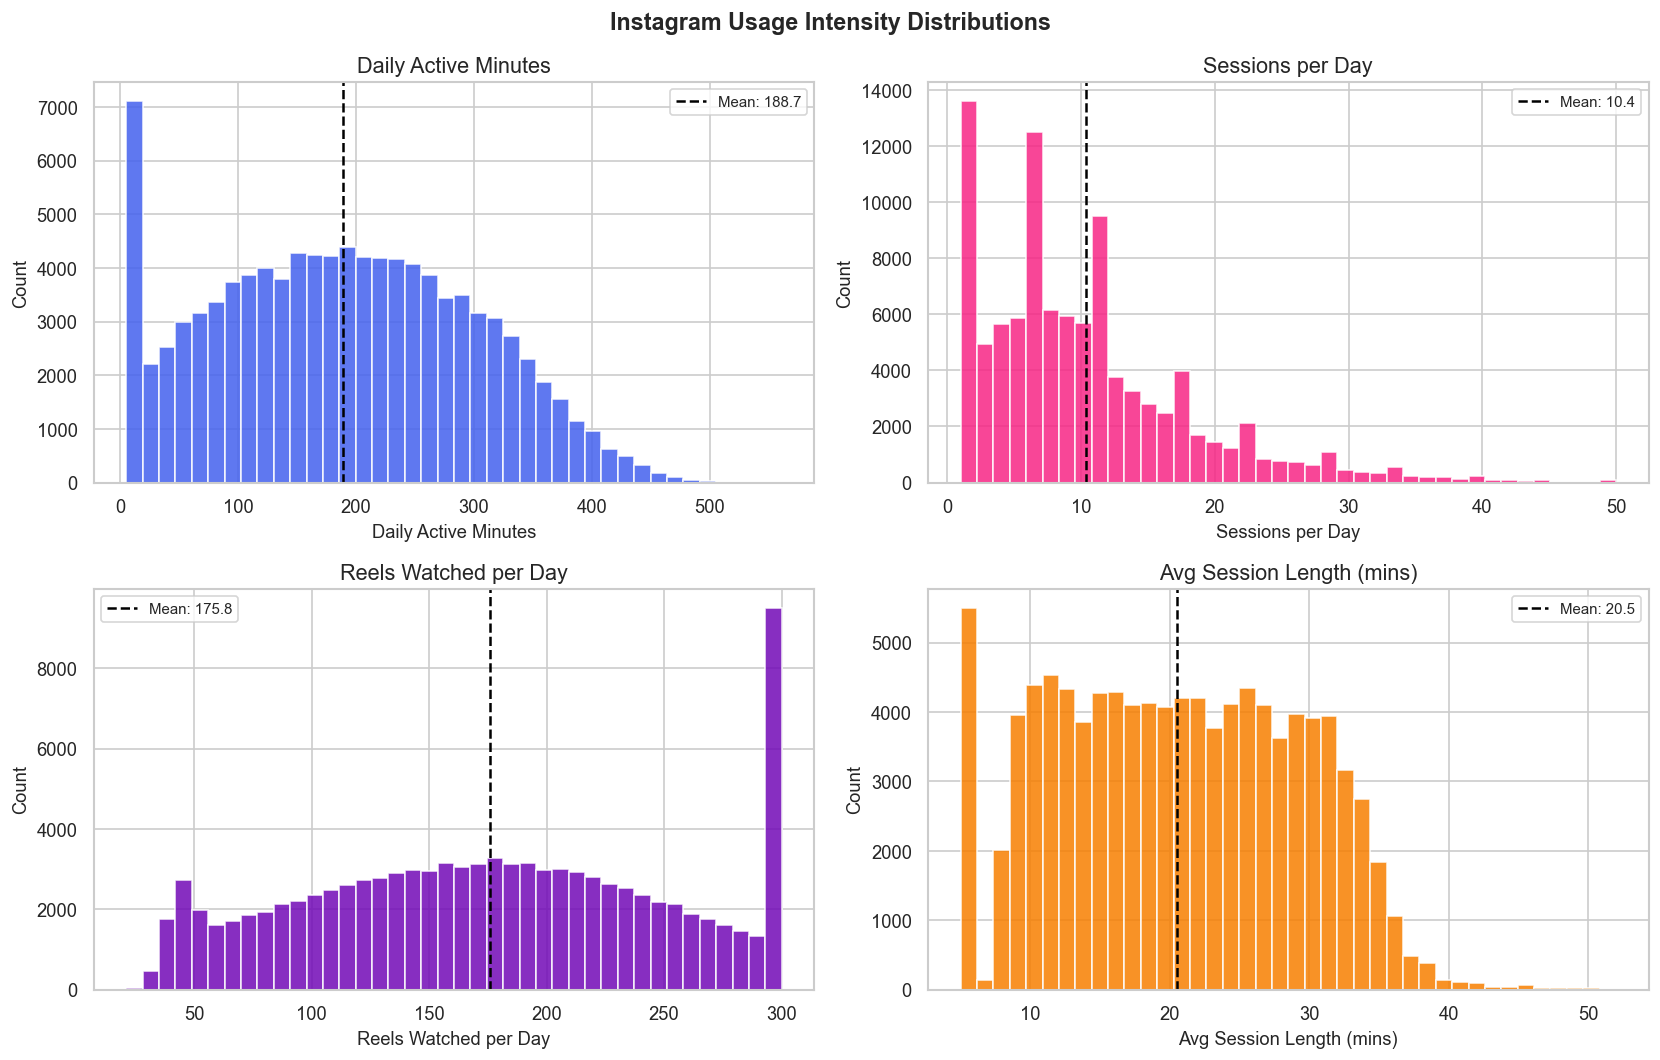

In [8]:
usage_cols = [
    ('daily_active_minutes_instagram', 'Daily Active Minutes'),
    ('sessions_per_day',               'Sessions per Day'),
    ('reels_watched_per_day',          'Reels Watched per Day'),
    ('average_session_length_minutes', 'Avg Session Length (mins)'),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
colors = ['#4361EE','#F72585','#7209B7','#F77F00']

for ax, (col, label), color in zip(axes.flat, usage_cols, colors):
    ax.hist(df[col], bins=40, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(df[col].mean(), color='black', lw=1.5, ls='--', label=f'Mean: {df[col].mean():.1f}')
    ax.set_title(label); ax.set_xlabel(label); ax.set_ylabel('Count'); ax.legend(fontsize=9)

plt.suptitle('Instagram Usage Intensity Distributions', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


### 5.4 — Psychological Score Distributions

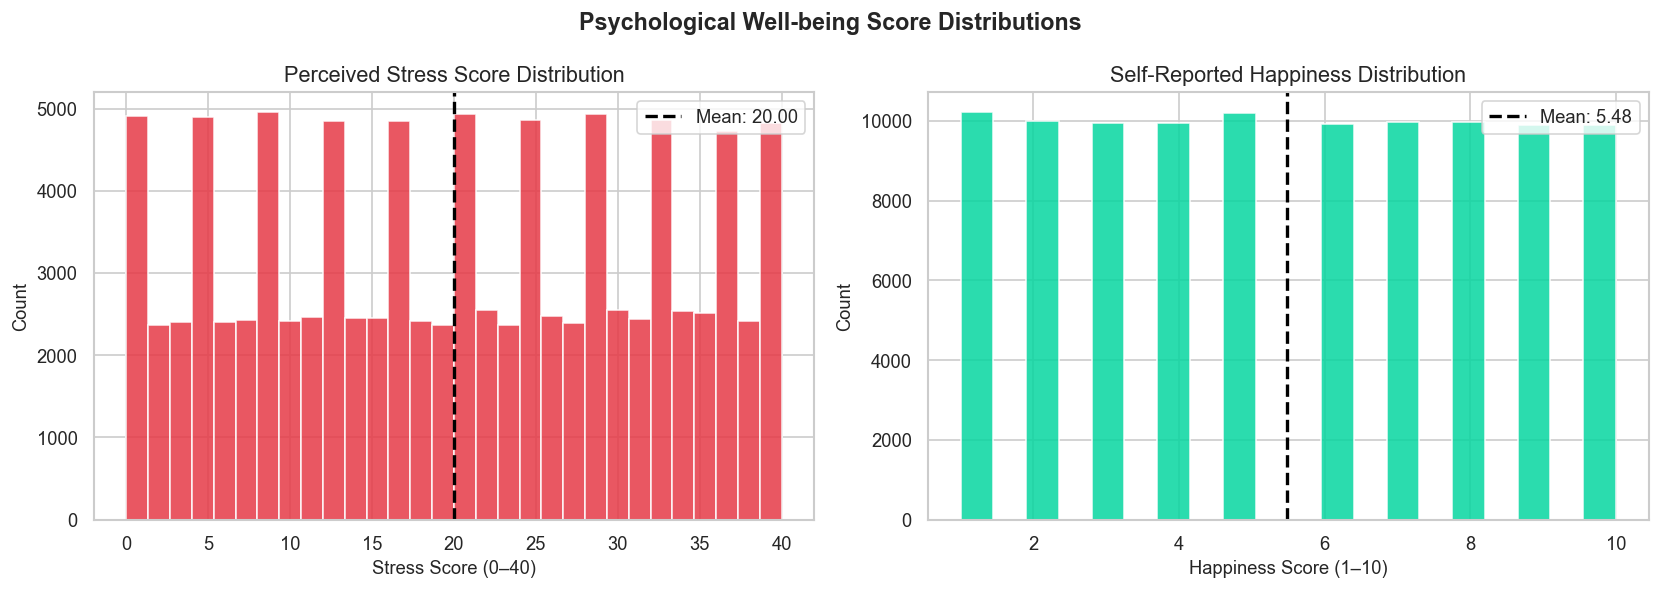

Stress    — Mean: 20.00 | Std: 11.81
Happiness — Mean: 5.48 | Std: 2.87


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['perceived_stress_score'], bins=30, color='#E63946', edgecolor='white', alpha=0.85)
axes[0].axvline(df['perceived_stress_score'].mean(), color='black', lw=2, ls='--',
                label=f"Mean: {df['perceived_stress_score'].mean():.2f}")
axes[0].set_title('Perceived Stress Score Distribution')
axes[0].set_xlabel('Stress Score (0–40)'); axes[0].set_ylabel('Count'); axes[0].legend()

axes[1].hist(df['self_reported_happiness'], bins=20, color='#06D6A0', edgecolor='white', alpha=0.85)
axes[1].axvline(df['self_reported_happiness'].mean(), color='black', lw=2, ls='--',
                label=f"Mean: {df['self_reported_happiness'].mean():.2f}")
axes[1].set_title('Self-Reported Happiness Distribution')
axes[1].set_xlabel('Happiness Score (1–10)'); axes[1].set_ylabel('Count'); axes[1].legend()

plt.suptitle('Psychological Well-being Score Distributions', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

print(f"Stress    — Mean: {df['perceived_stress_score'].mean():.2f} | Std: {df['perceived_stress_score'].std():.2f}")
print(f"Happiness — Mean: {df['self_reported_happiness'].mean():.2f} | Std: {df['self_reported_happiness'].std():.2f}")


# Step 6: Visualization Gallery
### Graph 1 — Age Distribution

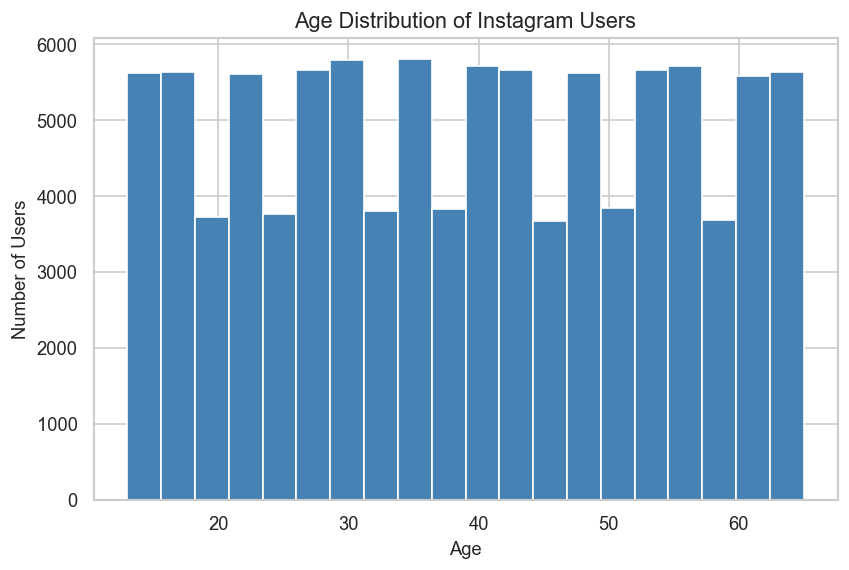

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df['age'], bins=20, color='steelblue', edgecolor='white')
plt.title('Age Distribution of Instagram Users')
plt.xlabel('Age'); plt.ylabel('Number of Users')
plt.savefig('graph01_age_distribution.png'); plt.show()


### Graph 2 — Gender Distribution

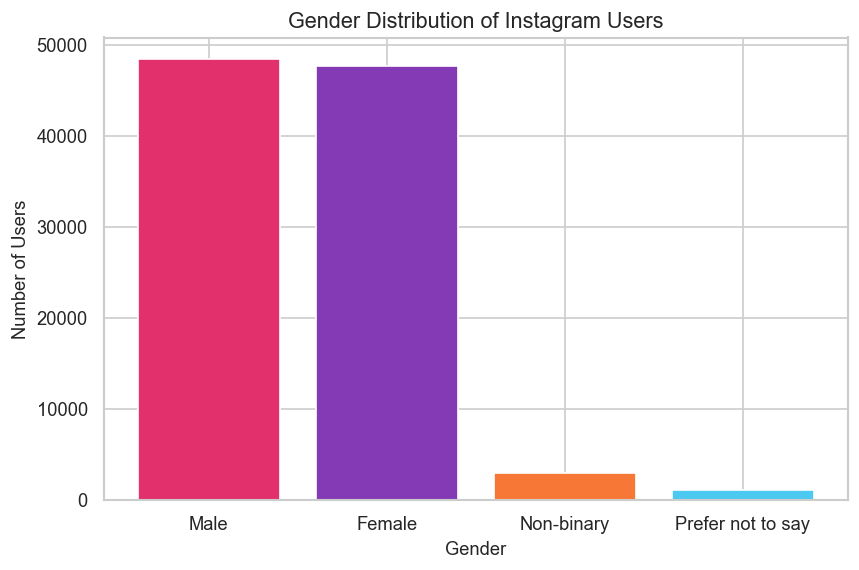

In [11]:
plt.figure(figsize=(8, 5))
g = df['gender'].value_counts()
plt.bar(g.index, g.values, color=['#E1306C','#833AB4','#F77737','#4CC9F0'], edgecolor='white')
plt.title('Gender Distribution of Instagram Users')
plt.xlabel('Gender'); plt.ylabel('Number of Users')
plt.savefig('graph02_gender.png'); plt.show()


### Graph 3 — Users by Country

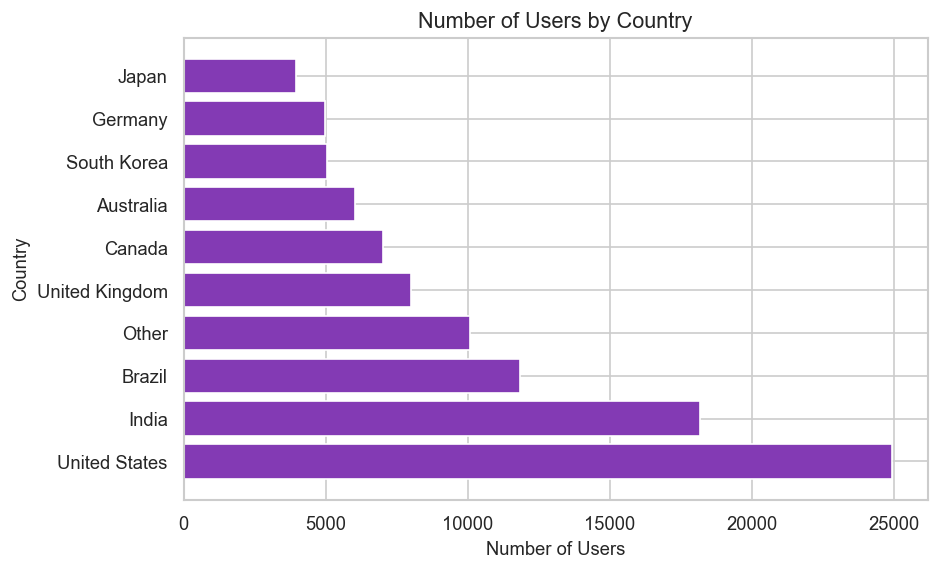

In [12]:
plt.figure(figsize=(8, 5))
c = df['country'].value_counts()
plt.barh(c.index, c.values, color='#833AB4', edgecolor='white')
plt.title('Number of Users by Country')
plt.xlabel('Number of Users'); plt.ylabel('Country')
plt.savefig('graph03_country.png'); plt.show()


#Graph 4 — Daily Active Minutes Distribution

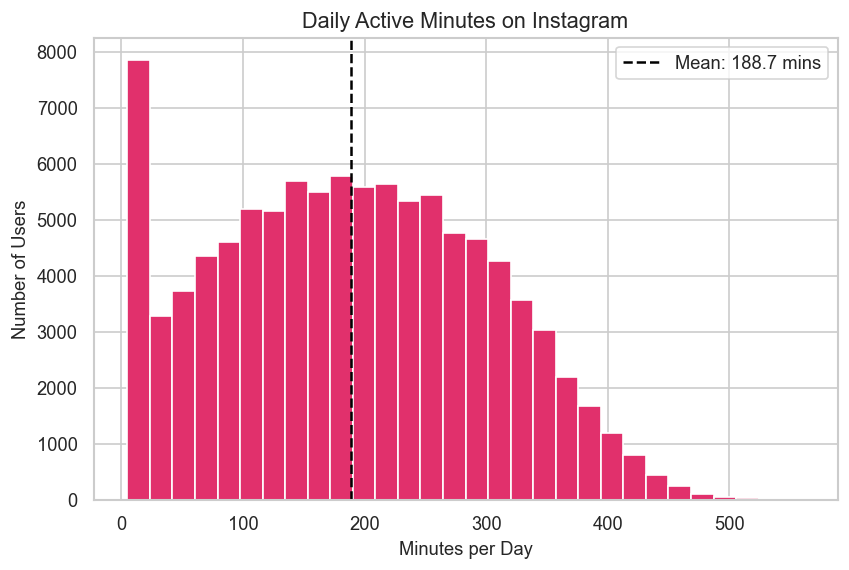

In [13]:
plt.figure(figsize=(8, 5))
plt.hist(df['daily_active_minutes_instagram'], bins=30, color='#E1306C', edgecolor='white')
plt.axvline(df['daily_active_minutes_instagram'].mean(), color='black', linestyle='--',
            label=f"Mean: {df['daily_active_minutes_instagram'].mean():.1f} mins")
plt.title('Daily Active Minutes on Instagram')
plt.xlabel('Minutes per Day'); plt.ylabel('Number of Users'); plt.legend()
plt.savefig('graph04_daily_minutes.png'); plt.show()


#Graph 5 — Stress Score Rises With Usage 

In [63]:
# usage_bucket already created in Step 4 setup cell above
# No need to redefine — running Step 4 cell once is enough


 Done — all variables ready


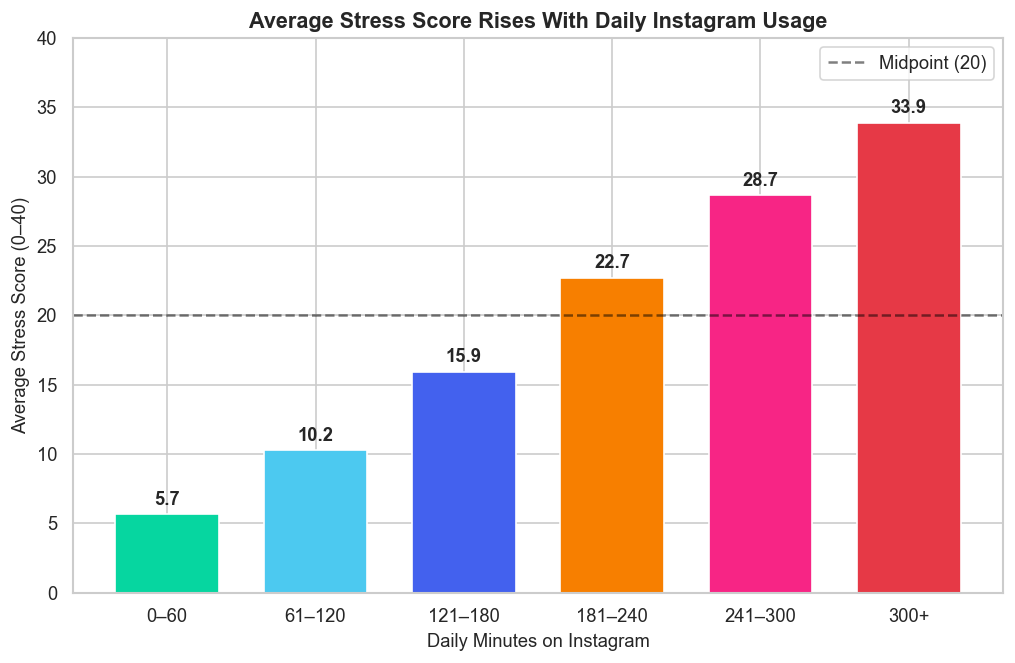

In [64]:
bucket_stress = df.groupby('usage_bucket', observed=True)['perceived_stress_score'].mean()

plt.figure(figsize=(10, 6))
bar_c = ['#06D6A0','#4CC9F0','#4361EE','#F77F00','#F72585','#E63946']
bars = plt.bar(bucket_stress.index, bucket_stress.values, color=bar_c, edgecolor='white', width=0.7)
for bar, val in zip(bars, bucket_stress.values):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.4, f'{val:.1f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.title('Average Stress Score Rises With Daily Instagram Usage', fontsize=13, fontweight='bold')
plt.xlabel('Daily Minutes on Instagram'); plt.ylabel('Average Stress Score (0–40)')
plt.ylim(0, 40)
plt.axhline(20, color='black', linestyle='--', lw=1.5, alpha=0.5, label='Midpoint (20)')
plt.legend()
plt.savefig('graph05_stress_by_usage.png', dpi=150); plt.show()


### Graph 6 — Happiness Declines as Usage Increases ⭐

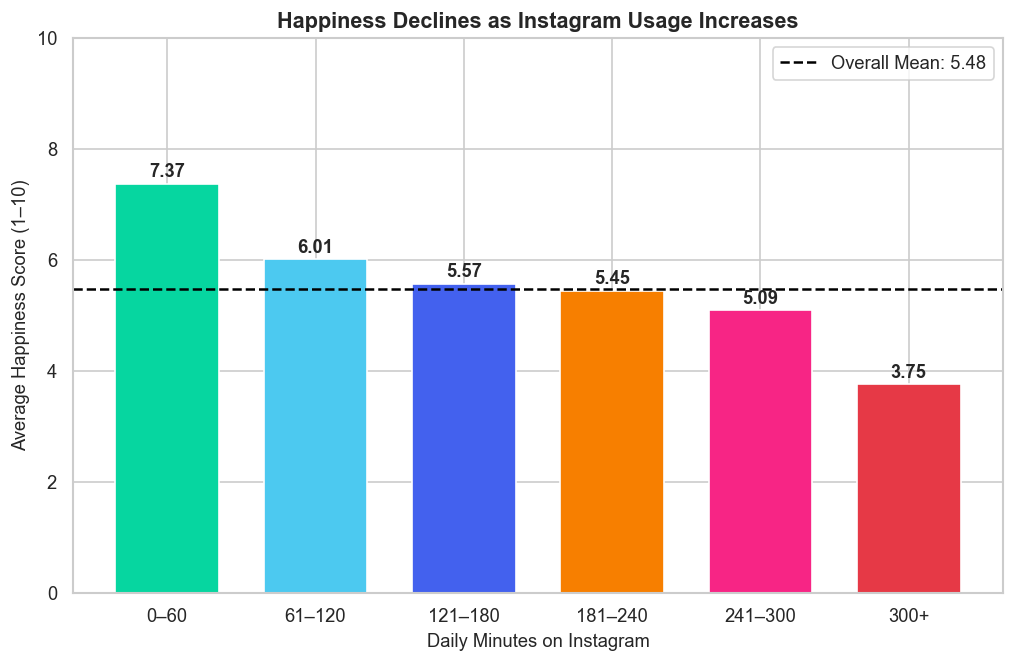

In [23]:
# Graph 6 — Happiness Declines as Instagram Usage Increases
bucket_happy = df.groupby('usage_bucket', observed=True)['self_reported_happiness'].mean()

plt.figure(figsize=(10, 6))
bar_c2 = ['#06D6A0','#4CC9F0','#4361EE','#F77F00','#F72585','#E63946']
bars = plt.bar(bucket_happy.index, bucket_happy.values, color=bar_c2, edgecolor='white', width=0.7)
for bar, val in zip(bars, bucket_happy.values):
    plt.text(bar.get_x()+bar.get_width()/2, val+0.05, f'{val:.2f}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.title('Happiness Declines as Instagram Usage Increases', fontsize=13, fontweight='bold')
plt.xlabel('Daily Minutes on Instagram'); plt.ylabel('Average Happiness Score (1–10)')
plt.ylim(0, 10)
plt.axhline(df['self_reported_happiness'].mean(), color='black', linestyle='--', lw=1.5,
            label=f"Overall Mean: {df['self_reported_happiness'].mean():.2f}")
plt.legend()
plt.savefig('graph06_happiness_by_usage.png', dpi=150); plt.show()


### Graph 7 — Daily Minutes vs Stress (Scatter + Trend Line)

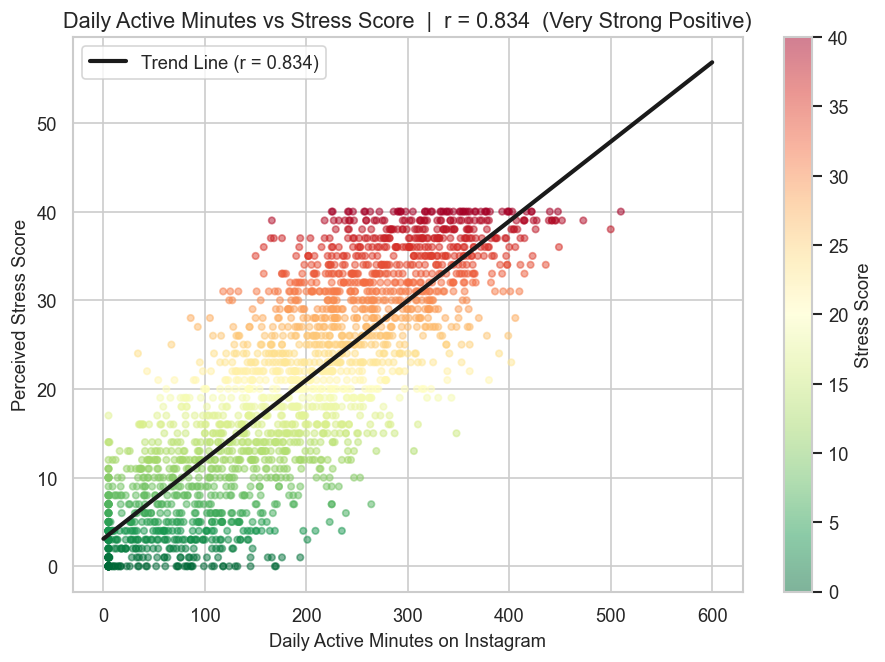

In [26]:
# Graph 7 — Daily Minutes vs Stress Score (Scatter + Trend Line)
r1, _ = pearsonr(df['daily_active_minutes_instagram'], df['perceived_stress_score'])
slope1, intercept1, _, _, _ = linregress(df['daily_active_minutes_instagram'], df['perceived_stress_score'])

plt.figure(figsize=(9, 6))
sc = plt.scatter(sample['daily_active_minutes_instagram'], sample['perceived_stress_score'],
                 c=sample['perceived_stress_score'], cmap='RdYlGn_r', alpha=0.5, s=15)
plt.colorbar(sc, label='Stress Score')
plt.plot(x_line, slope1*x_line+intercept1, 'k-', lw=2.5, label=f'Trend Line (r = {r1:.3f})')
plt.title(f'Daily Active Minutes vs Stress Score  |  r = {r1:.3f}  (Very Strong Positive)')
plt.xlabel('Daily Active Minutes on Instagram'); plt.ylabel('Perceived Stress Score')
plt.legend(); plt.savefig('graph07_minutes_vs_stress.png', dpi=150); plt.show()


### Graph 8 — Daily Minutes vs Happiness (Scatter + Trend Line)

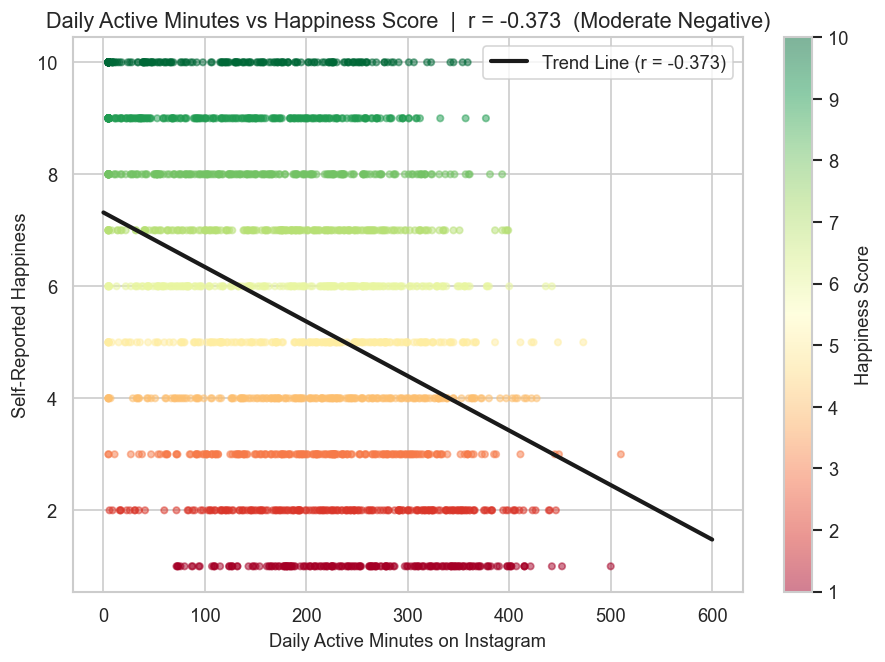

In [27]:
# Graph 8 — Daily Minutes vs Happiness Score (Scatter + Trend Line)
r2, _ = pearsonr(df['daily_active_minutes_instagram'], df['self_reported_happiness'])
slope2, intercept2, _, _, _ = linregress(df['daily_active_minutes_instagram'], df['self_reported_happiness'])

plt.figure(figsize=(9, 6))
sc2 = plt.scatter(sample['daily_active_minutes_instagram'], sample['self_reported_happiness'],
                  c=sample['self_reported_happiness'], cmap='RdYlGn', alpha=0.5, s=15)
plt.colorbar(sc2, label='Happiness Score')
plt.plot(x_line, slope2*x_line+intercept2, 'k-', lw=2.5, label=f'Trend Line (r = {r2:.3f})')
plt.title(f'Daily Active Minutes vs Happiness Score  |  r = {r2:.3f}  (Moderate Negative)')
plt.xlabel('Daily Active Minutes on Instagram'); plt.ylabel('Self-Reported Happiness')
plt.legend(); plt.savefig('graph08_minutes_vs_happiness.png', dpi=150); plt.show()


### Graph 9 — Average Stress Score by Gender

In [50]:
# stress_group and age_group already created in Step 4 setup cell
# Just confirming variables are ready for Graph 9
print('✅ stress_group ready:', df['stress_group'].nunique(), 'groups')


✅ Done


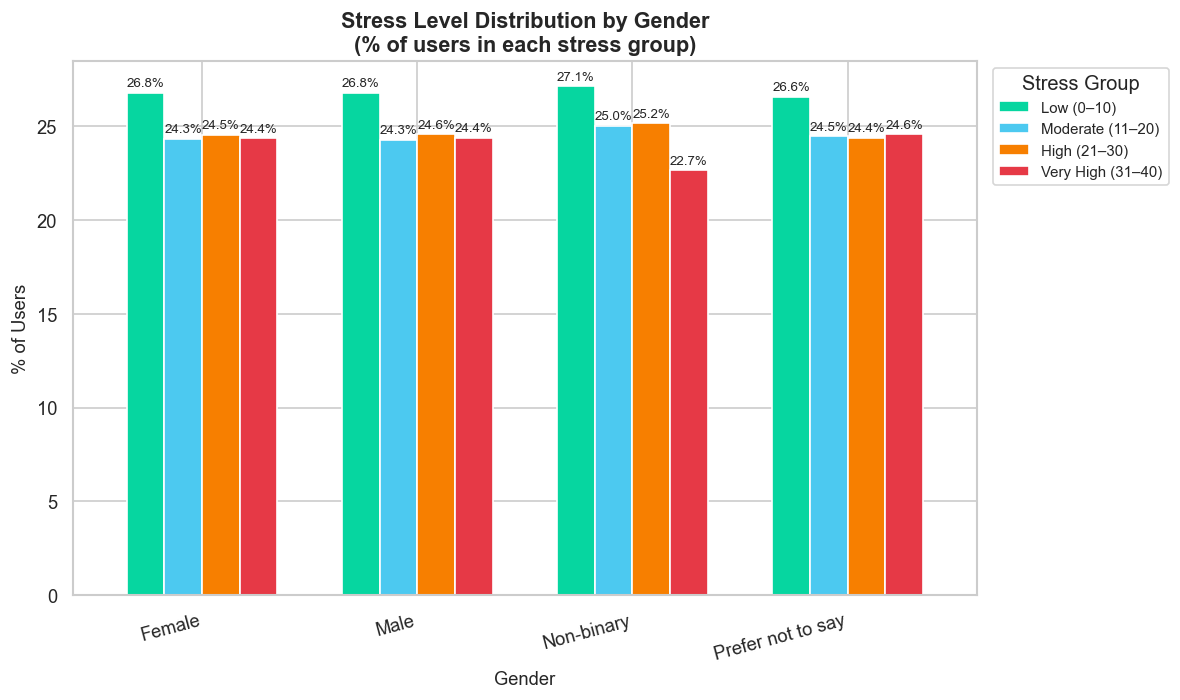

In [51]:
# Graph 9 — Stress Level Distribution by Gender (Grouped Bar)
ct = pd.crosstab(df['gender'], df['stress_group'], normalize='index') * 100
fig, ax = plt.subplots(figsize=(10, 6))
ct.plot(kind='bar', ax=ax, color=['#06D6A0','#4CC9F0','#F77F00','#E63946'],
        edgecolor='white', width=0.7)
ax.set_title('Stress Level Distribution by Gender\n(% of users in each stress group)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Gender'); ax.set_ylabel('% of Users')
ax.set_xticklabels(ct.index, rotation=15, ha='right')
ax.legend(title='Stress Group', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%', fontsize=8, padding=2)
plt.tight_layout(); plt.show()


### Graph 10 — Average Stress Score by Country

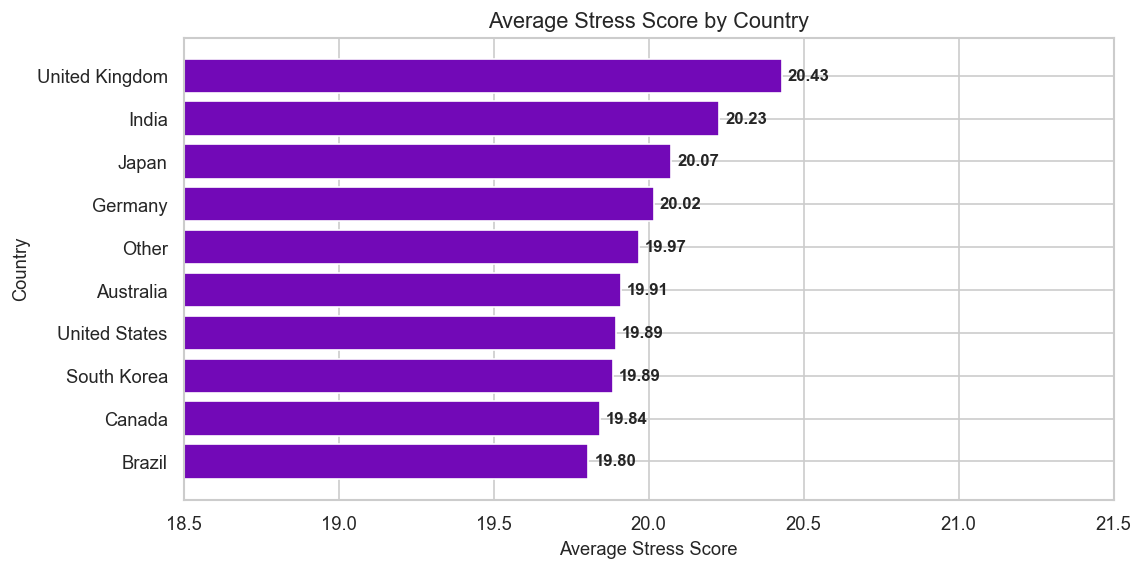

In [28]:
plt.figure(figsize=(10, 5))
avg_sc = df.groupby('country')['perceived_stress_score'].mean().sort_values()
bars = plt.barh(avg_sc.index, avg_sc.values, color='#7209B7', edgecolor='white')
plt.xlim(18.5, 21.5)
for bar in bars:
    plt.text(bar.get_width()+0.02, bar.get_y()+bar.get_height()/2,
             f'{bar.get_width():.2f}', va='center', fontsize=10, fontweight='bold')
plt.title('Average Stress Score by Country')
plt.xlabel('Average Stress Score'); plt.ylabel('Country')
plt.savefig('graph10_stress_by_country.png', dpi=150); plt.show()


### Graph 11 — Average Stress by Income Level

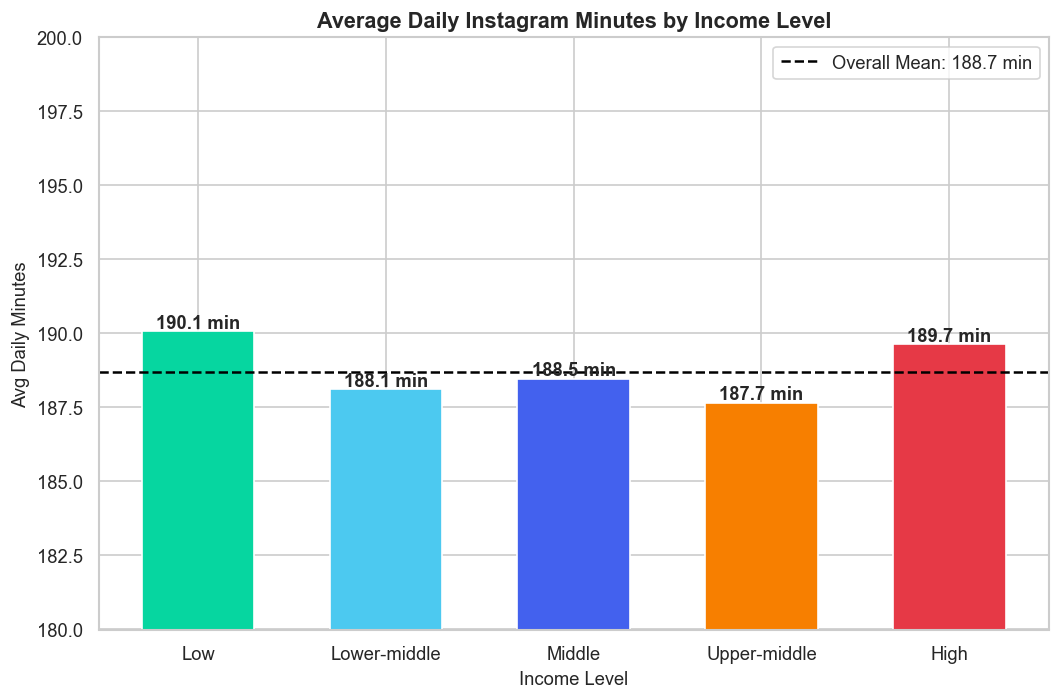

In [47]:
# Graph 11 — Avg Daily Instagram Minutes by Income Level
income_order = ['Low','Lower-middle','Middle','Upper-middle','High']
avg_mins_income = df.groupby('income_level')['daily_active_minutes_instagram'].mean().reindex(income_order)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.bar(avg_mins_income.index, avg_mins_income.values,
              color=['#06D6A0','#4CC9F0','#4361EE','#F77F00','#E63946'], edgecolor='white', width=0.6)
ax.set_ylim(180, 200)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
            f'{bar.get_height():.1f} min', ha='center', fontsize=11, fontweight='bold')
ax.axhline(df['daily_active_minutes_instagram'].mean(), color='black', lw=1.5, linestyle='--',
           label=f"Overall Mean: {df['daily_active_minutes_instagram'].mean():.1f} min")
ax.set_title('Average Daily Instagram Minutes by Income Level', fontsize=13, fontweight='bold')
ax.set_xlabel('Income Level'); ax.set_ylabel('Avg Daily Minutes'); ax.legend()
plt.tight_layout(); plt.show()


### Graph 12 — Reels Watched vs Stress Score

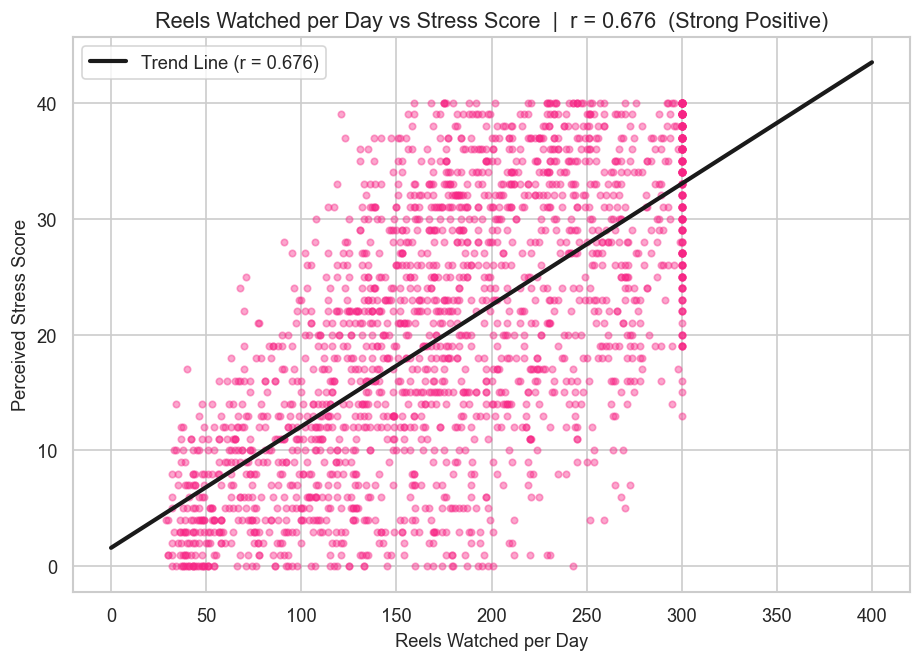

In [30]:
r3, _ = pearsonr(df['reels_watched_per_day'], df['perceived_stress_score'])
slope3, intercept3, _, _, _ = linregress(df['reels_watched_per_day'], df['perceived_stress_score'])
x3 = np.linspace(0, 400, 200)

plt.figure(figsize=(9, 6))
plt.scatter(sample['reels_watched_per_day'], sample['perceived_stress_score'],
            color='#F72585', alpha=0.4, s=15)
plt.plot(x3, slope3*x3+intercept3, 'k-', lw=2.5, label=f'Trend Line (r = {r3:.3f})')
plt.title(f'Reels Watched per Day vs Stress Score  |  r = {r3:.3f}  (Strong Positive)')
plt.xlabel('Reels Watched per Day'); plt.ylabel('Perceived Stress Score')
plt.legend(); plt.savefig('graph12_reels_vs_stress.png', dpi=150); plt.show()


### Graph 13 — Average Happiness Score by Country

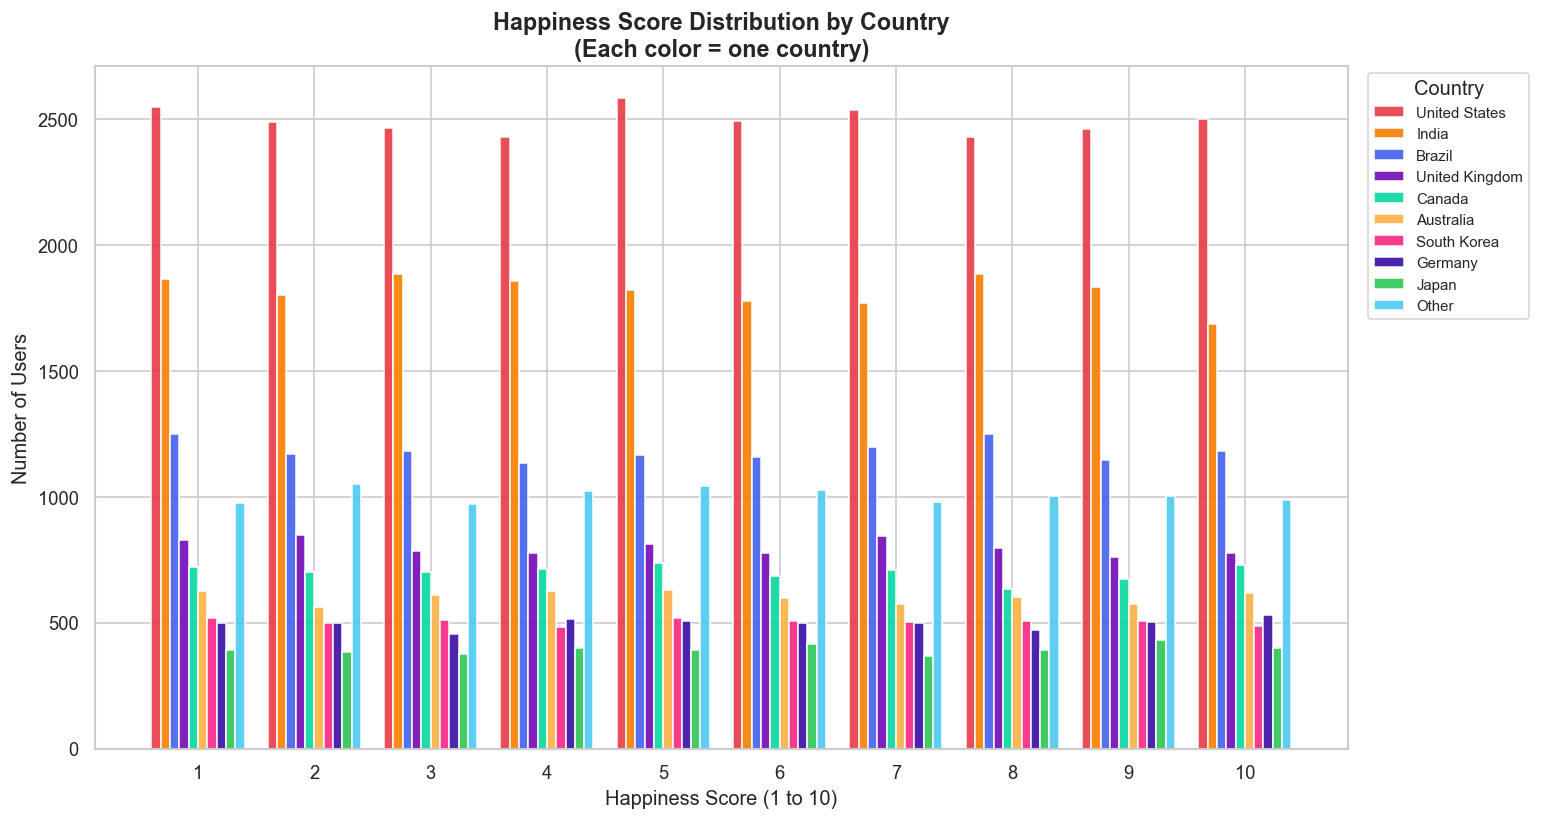

In [69]:
#CHART 13 — Happiness Score Distribution by Country (x-axis 1–10, different colors)
fig, ax = plt.subplots(figsize=(13, 7))
happiness_scores = list(range(1, 11))
x = np.arange(len(happiness_scores))
bar_width = 0.08

for i, country in enumerate(country_order):
    sub    = df[df['country'] == country]
    counts = sub['self_reported_happiness'].value_counts().sort_index()
    vals   = [counts.get(s, 0) for s in happiness_scores]
    ax.bar(x + i*bar_width, vals, bar_width,
           label=country, color=country_colors[country], edgecolor='white', alpha=0.9)

ax.set_xticks(x + bar_width*4.5)
ax.set_xticklabels([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], fontsize=11)
ax.set_xlabel('Happiness Score (1 to 10)', fontsize=12)
ax.set_ylabel('Number of Users', fontsize=12)
ax.set_title('Happiness Score Distribution by Country\n(Each color = one country)',
             fontsize=14, fontweight='bold')
ax.legend(title='Country', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

### Graph 14 — Sessions per Day vs Stress Score

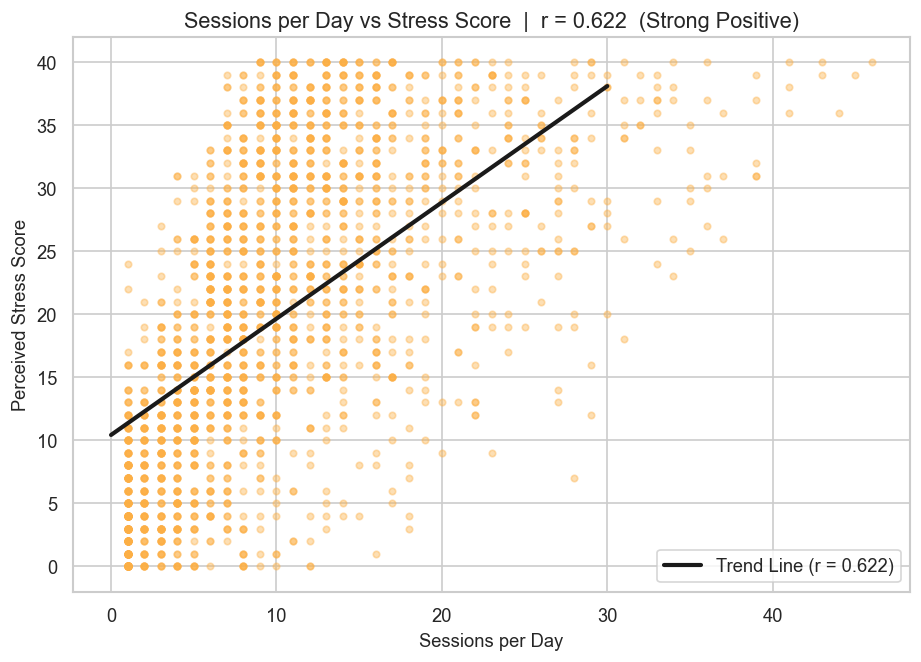

In [33]:
r4, _ = pearsonr(df['sessions_per_day'], df['perceived_stress_score'])
slope4, intercept4, _, _, _ = linregress(df['sessions_per_day'], df['perceived_stress_score'])
x4 = np.linspace(0, 30, 100)

plt.figure(figsize=(9, 6))
plt.scatter(sample['sessions_per_day'], sample['perceived_stress_score'],
            color='#FCAF45', alpha=0.4, s=15)
plt.plot(x4, slope4*x4+intercept4, 'k-', lw=2.5, label=f'Trend Line (r = {r4:.3f})')
plt.title(f'Sessions per Day vs Stress Score  |  r = {r4:.3f}  (Strong Positive)')
plt.xlabel('Sessions per Day'); plt.ylabel('Perceived Stress Score')
plt.legend(); plt.savefig('graph14_sessions_vs_stress.png', dpi=150); plt.show()


### Graph 15 — Subscription Status (Pie Chart)

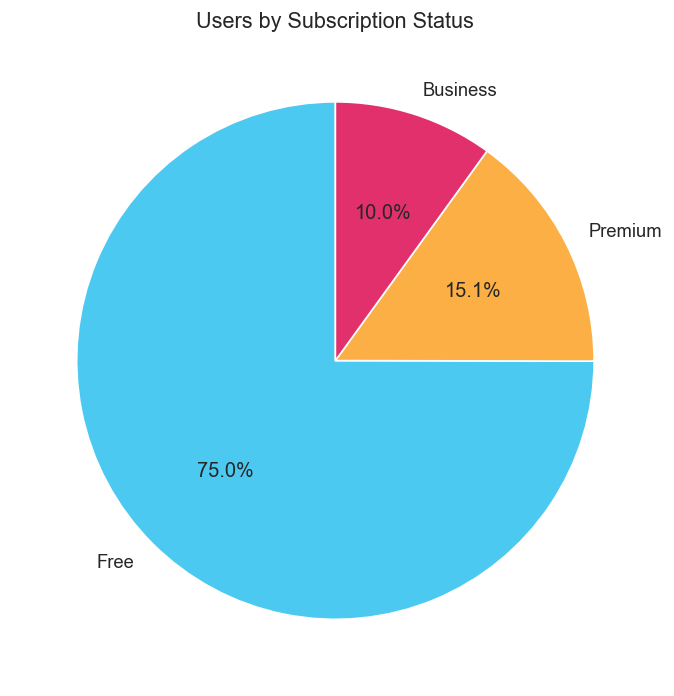

In [34]:
plt.figure(figsize=(7, 7))
sub = df['subscription_status'].value_counts()
plt.pie(sub, labels=sub.index, autopct='%1.1f%%',
        colors=['#4CC9F0','#FCAF45','#E1306C'], startangle=90)
plt.title('Users by Subscription Status')
plt.savefig('graph15_subscription.png', dpi=150); plt.show()


### Graph 16 — Content Type vs Avg Stress & Usage ⭐

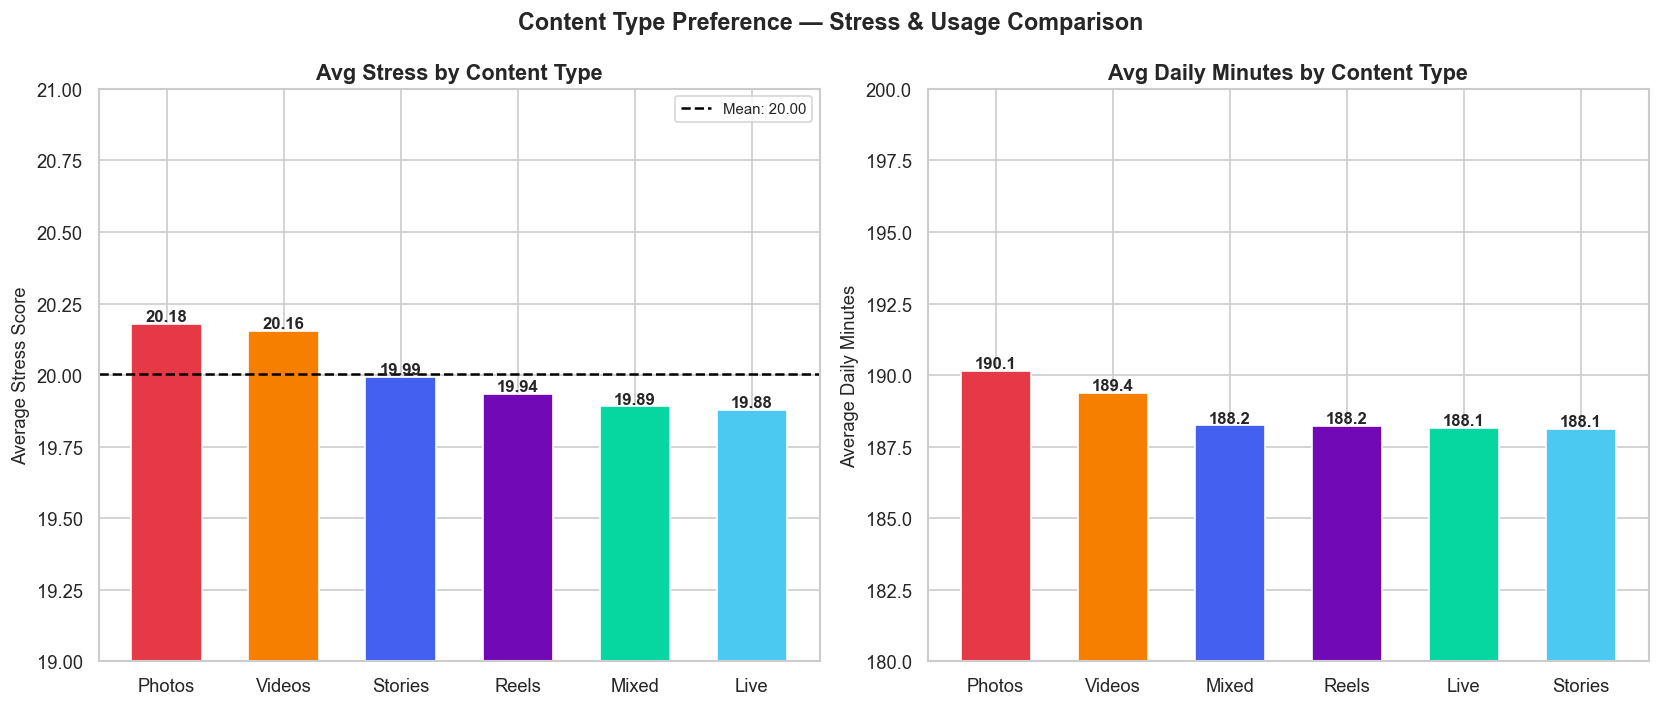

In [35]:
ct_stress = df.groupby('content_type_preference')['perceived_stress_score'].mean().sort_values(ascending=False)
ct_mins   = df.groupby('content_type_preference')['daily_active_minutes_instagram'].mean().sort_values(ascending=False)
ct_colors = ['#E63946','#F77F00','#4361EE','#7209B7','#06D6A0','#4CC9F0']

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

bars1 = axes[0].bar(ct_stress.index, ct_stress.values, color=ct_colors, edgecolor='white', width=0.6)
axes[0].set_ylim(19.0, 21.0)
for bar in bars1:
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01,
                 f'{bar.get_height():.2f}', ha='center', fontsize=10, fontweight='bold')
axes[0].axhline(df['perceived_stress_score'].mean(), color='black', lw=1.5, linestyle='--',
                label=f"Mean: {df['perceived_stress_score'].mean():.2f}")
axes[0].set_title('Avg Stress by Content Type', fontweight='bold')
axes[0].set_ylabel('Average Stress Score'); axes[0].legend(fontsize=9)

bars2 = axes[1].bar(ct_mins.index, ct_mins.values, color=ct_colors, edgecolor='white', width=0.6)
axes[1].set_ylim(180, 200)
for bar in bars2:
    axes[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.1,
                 f'{bar.get_height():.1f}', ha='center', fontsize=10, fontweight='bold')
axes[1].set_title('Avg Daily Minutes by Content Type', fontweight='bold')
axes[1].set_ylabel('Average Daily Minutes')

plt.suptitle('Content Type Preference — Stress & Usage Comparison', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('graph16_content_type.png', dpi=150); plt.show()


# Graph 17 — Number of Users by Country

In [65]:
# Dates already parsed in Step 4 setup cell
# country_colors and country_order also already defined there
print('✅ Date columns and country variables ready')


 Date columns ready


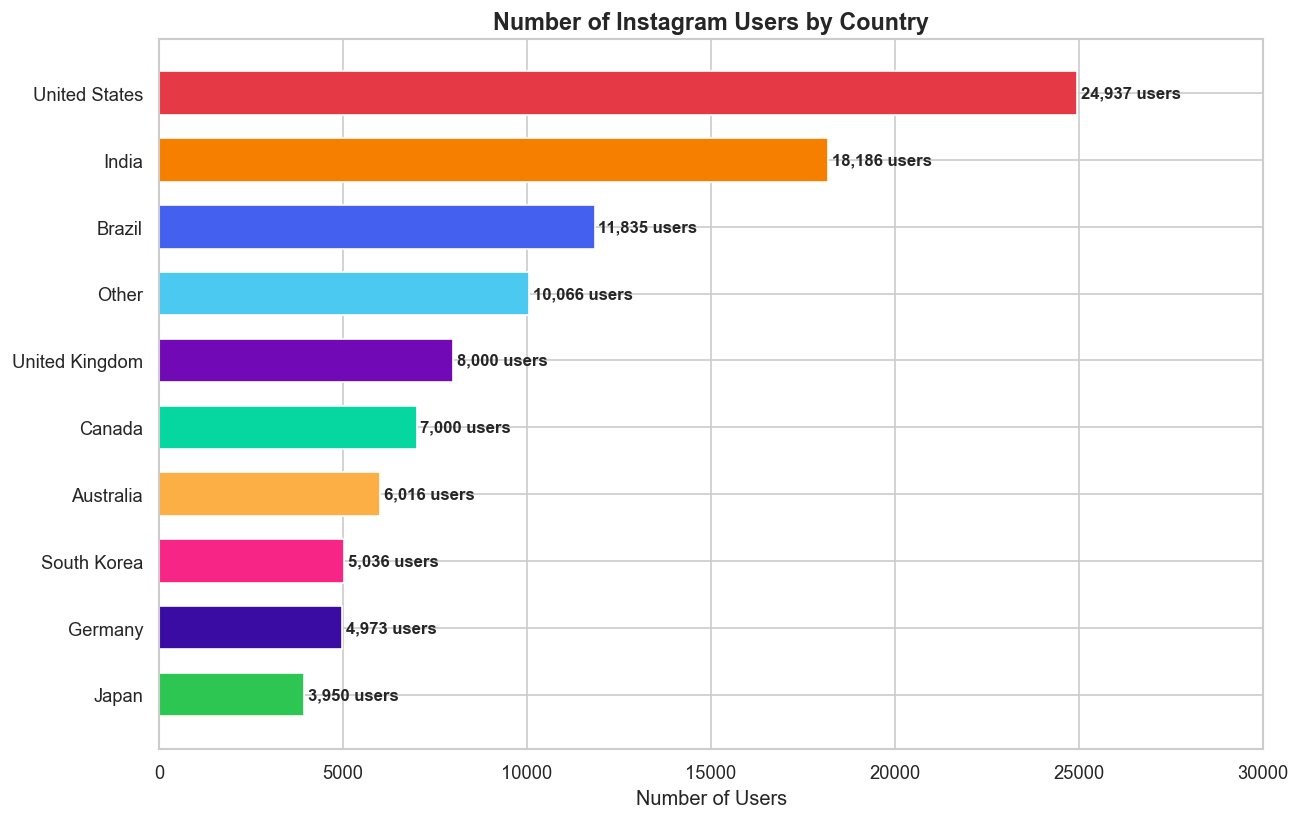

In [66]:
# CHART 17 — Number of Users by Country 
fig, ax = plt.subplots(figsize=(11, 7))
c_counts = df['country'].value_counts().sort_values()
colors1  = [country_colors[c] for c in c_counts.index]
bars = ax.barh(c_counts.index, c_counts.values, color=colors1, edgecolor='white', height=0.65)
for bar in bars:
    ax.text(bar.get_width()+100, bar.get_y()+bar.get_height()/2,
            f'{bar.get_width():,} users', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Number of Users', fontsize=12)
ax.set_title('Number of Instagram Users by Country', fontsize=14, fontweight='bold')
ax.set_xlim(0, 30000)
plt.tight_layout(); plt.show()

### Graph 18 — Average Stress by Employment Status

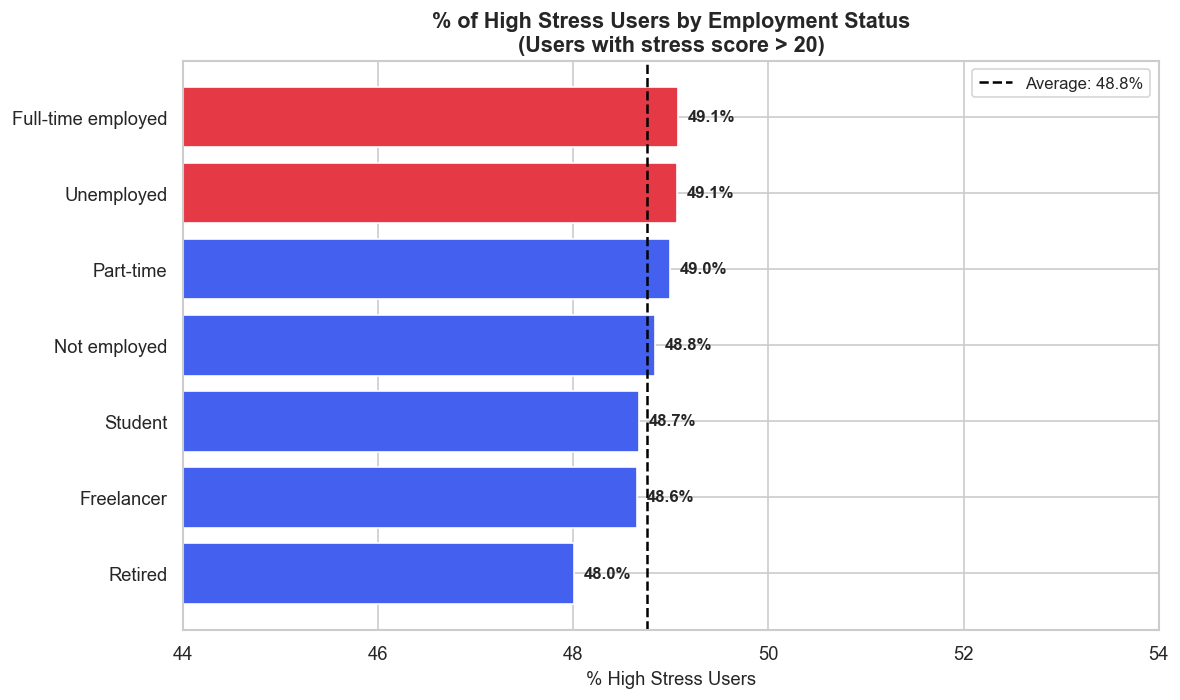

In [48]:
# Graph 18 — % High Stress Users by Employment Status
hs_emp = df.groupby('employment_status').apply(lambda x: (x['perceived_stress_score'] > 20).mean() * 100).sort_values()
colors = ['#4361EE' if v < 49 else '#E63946' for v in hs_emp.values]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(hs_emp.index, hs_emp.values, color=colors, edgecolor='white')
for bar in bars:
    ax.text(bar.get_width()+0.1, bar.get_y()+bar.get_height()/2,
            f'{bar.get_width():.1f}%', va='center', fontsize=10, fontweight='bold')
ax.axvline(hs_emp.mean(), color='black', lw=1.5, linestyle='--',
           label=f'Average: {hs_emp.mean():.1f}%')
ax.set_xlim(44, 54)
ax.set_title('% of High Stress Users by Employment Status\n(Users with stress score > 20)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('% High Stress Users'); ax.legend(fontsize=10)
plt.tight_layout(); plt.show()


### Graph 19 — Average Happiness Score by Gender

In [54]:
# age_group already created in Step 4 setup cell
print('✅ age_group ready:', df['age_group'].nunique(), 'groups')


 Done


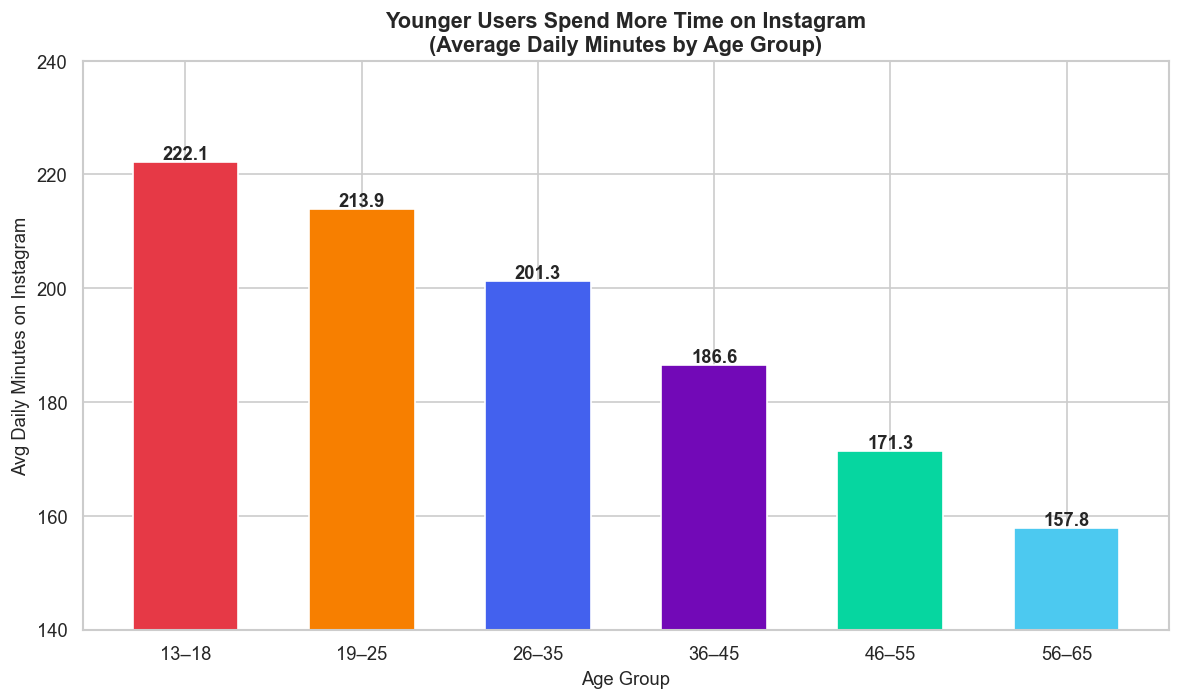

In [55]:
# Graph 19 — Avg Daily Minutes by Age Group (clear downward trend)
avg_mins_age = df.groupby('age_group', observed=True)['daily_active_minutes_instagram'].mean()

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(avg_mins_age.index, avg_mins_age.values,
              color=['#E63946','#F77F00','#4361EE','#7209B7','#06D6A0','#4CC9F0'],
              edgecolor='white', width=0.6)
for bar, val in zip(bars, avg_mins_age.values):
    ax.text(bar.get_x()+bar.get_width()/2, val+0.5,
            f'{val:.1f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(140, 240)
ax.set_title('Younger Users Spend More Time on Instagram\n(Average Daily Minutes by Age Group)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Age Group'); ax.set_ylabel('Avg Daily Minutes on Instagram')
plt.tight_layout(); plt.show()


### Graph 20 — High vs Low Stress Users: 3.7× Usage Difference ⭐

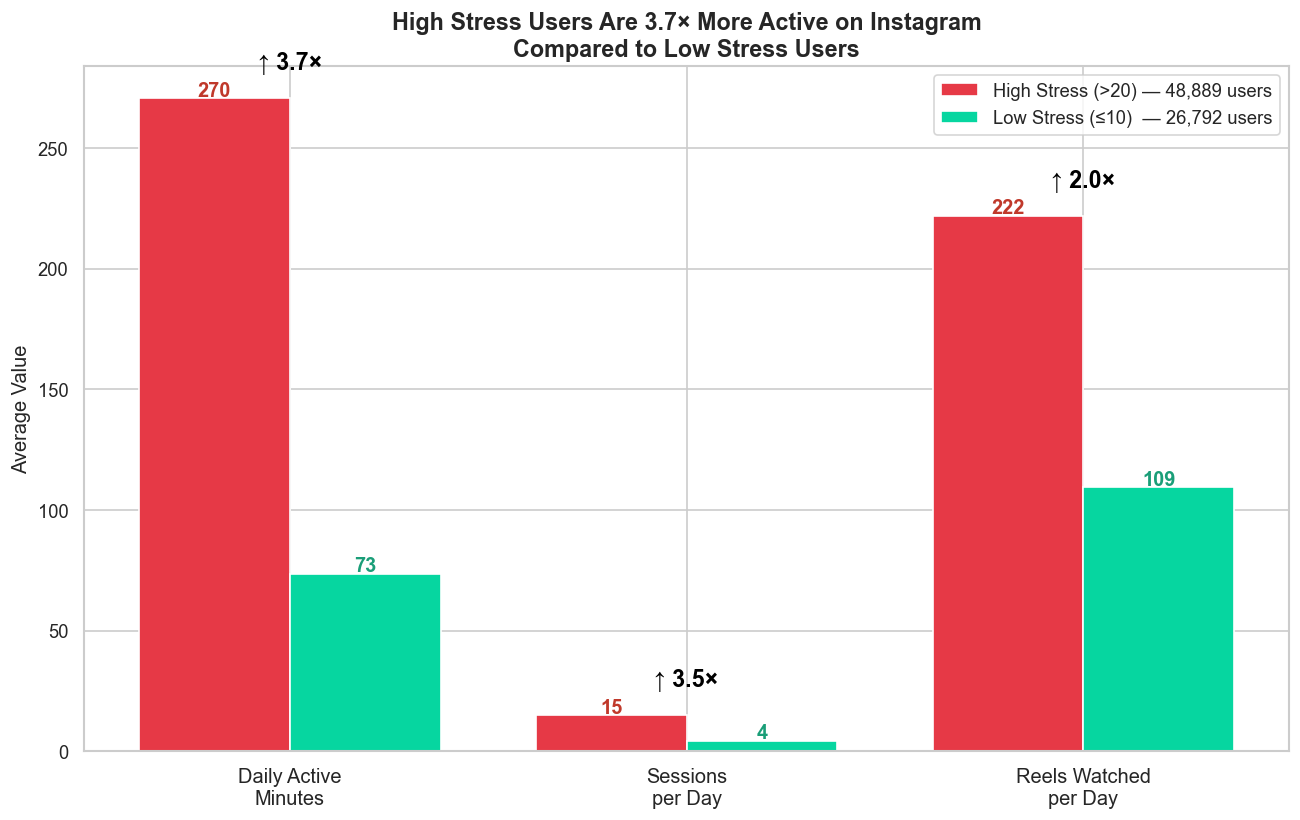

In [41]:
high = df[df['perceived_stress_score'] > 20]
low  = df[df['perceived_stress_score'] <= 10]

categories = ['Daily Active\nMinutes', 'Sessions\nper Day', 'Reels Watched\nper Day']
high_means = [high['daily_active_minutes_instagram'].mean(),
              high['sessions_per_day'].mean(),
              high['reels_watched_per_day'].mean()]
low_means  = [low['daily_active_minutes_instagram'].mean(),
              low['sessions_per_day'].mean(),
              low['reels_watched_per_day'].mean()]

x = np.arange(len(categories)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 7))
b1 = ax.bar(x-w/2, high_means, w, label=f'High Stress (>20) — {len(high):,} users',
            color='#E63946', edgecolor='white')
b2 = ax.bar(x+w/2, low_means,  w, label=f'Low Stress (≤10)  — {len(low):,} users',
            color='#06D6A0', edgecolor='white')

for bar, val in zip(b1, high_means):
    ax.text(bar.get_x()+bar.get_width()/2, val+1, f'{val:.0f}',
            ha='center', fontsize=12, fontweight='bold', color='#c0392b')
for bar, val in zip(b2, low_means):
    ax.text(bar.get_x()+bar.get_width()/2, val+1, f'{val:.0f}',
            ha='center', fontsize=12, fontweight='bold', color='#1a9e78')
for i, (h, l) in enumerate(zip(high_means, low_means)):
    ax.text(x[i], max(h,l)+12, f'↑ {h/l:.1f}×', ha='center',
            fontsize=14, fontweight='bold', color='black')

ax.set_xticks(x); ax.set_xticklabels(categories, fontsize=12)
ax.set_ylabel('Average Value', fontsize=12)
ax.set_title('High Stress Users Are 3.7× More Active on Instagram\nCompared to Low Stress Users',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('graph20_high_vs_low_stress.png', dpi=150); plt.show()


In [ ]:
print("=" * 45)
print("  ✅ All 20 Graphs Generated and Saved!")
print("=" * 45)


# Step 7: Correlation Analysis
### 7.1 — Full Correlation Heatmap

In [56]:
# num_cols already defined in Step 4 setup cell
print('✅ num_cols ready:', len(num_cols), 'numeric columns')


 Done


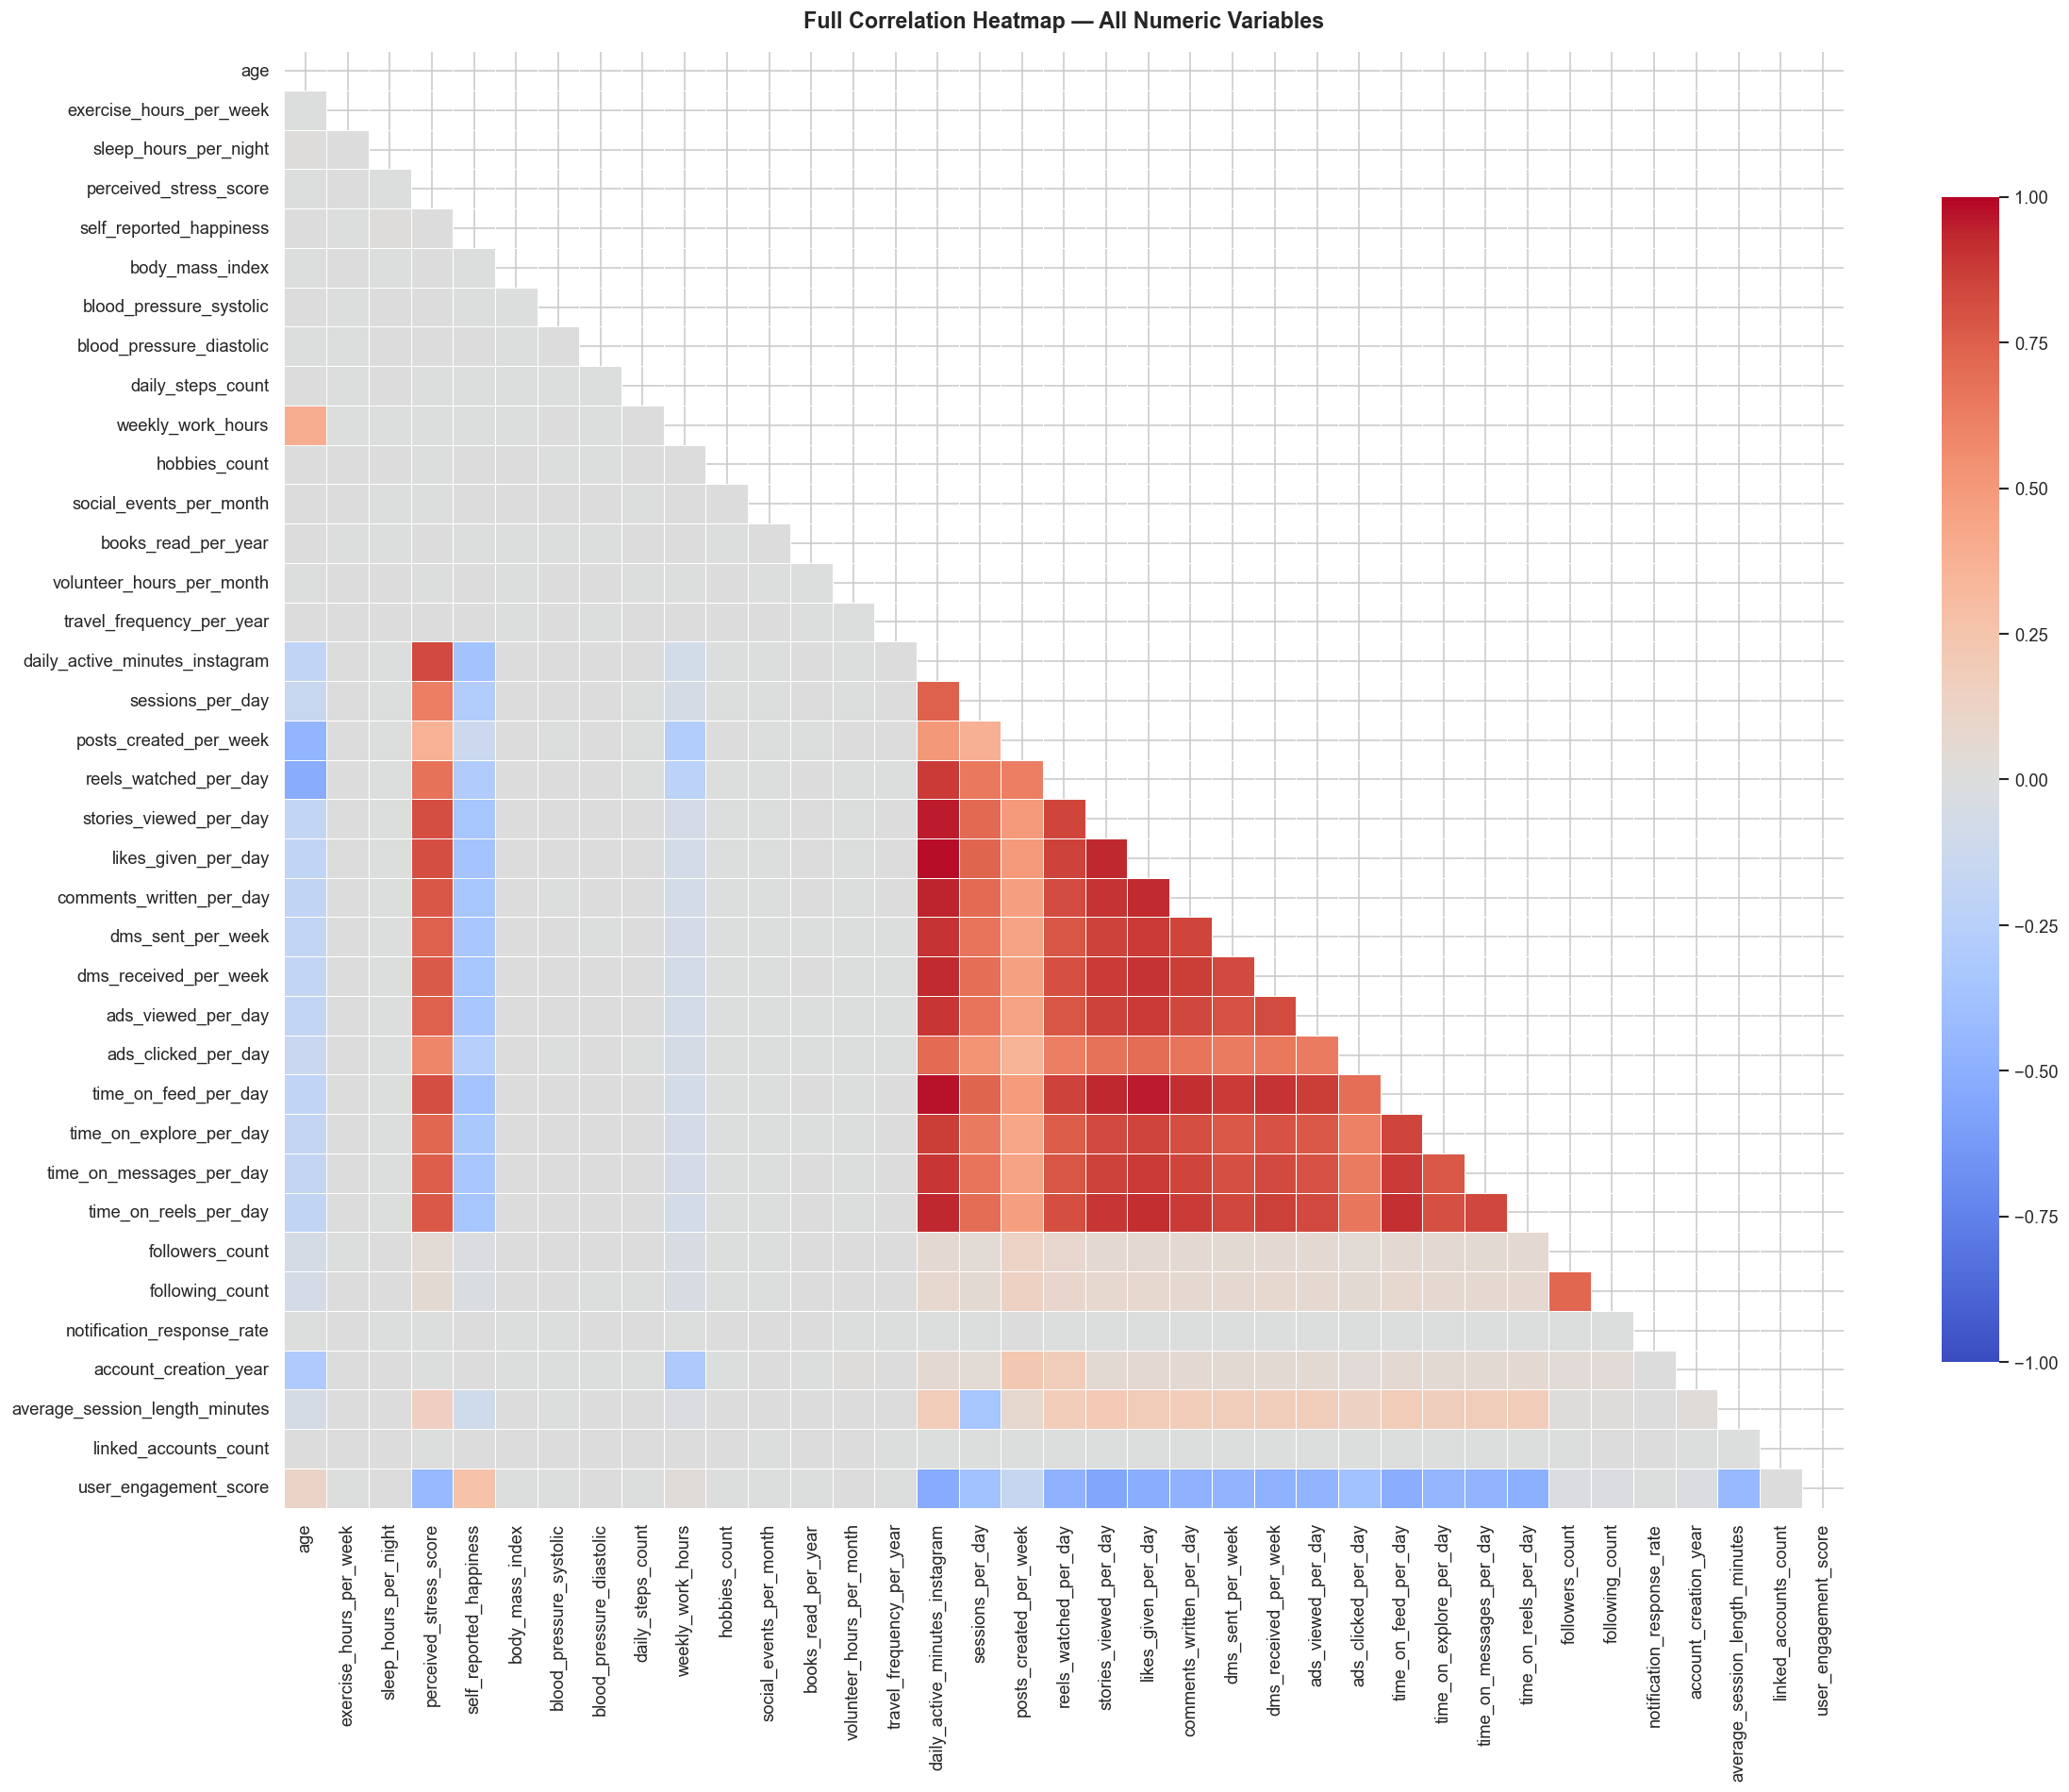

In [57]:
corr_matrix = df[num_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

plt.figure(figsize=(20, 16))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='coolwarm', center=0,
            linewidths=0.3, vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
plt.title('Full Correlation Heatmap — All Numeric Variables', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout(); plt.show()


### 7.2 — Key Variable Correlation Heatmap (Annotated)

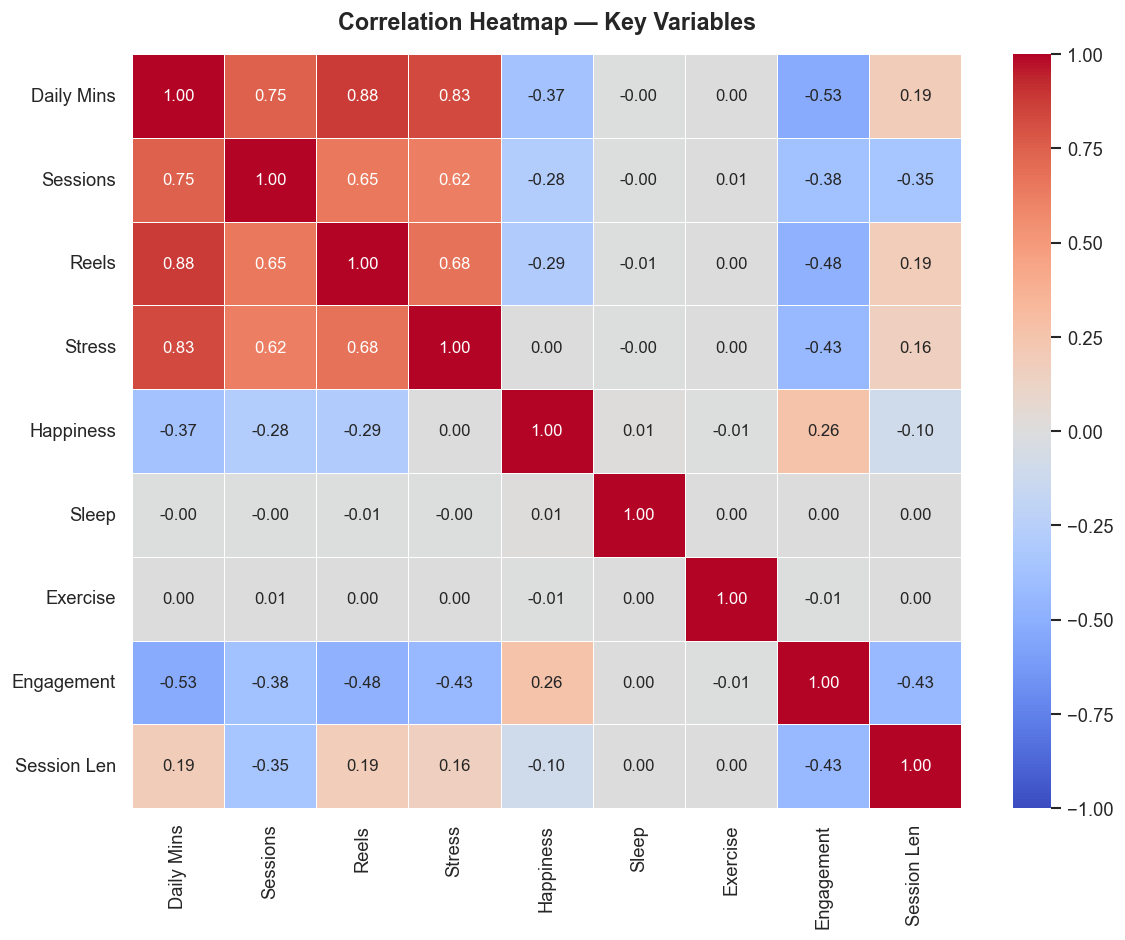

In [43]:
key_cols = ['daily_active_minutes_instagram','sessions_per_day','reels_watched_per_day',
            'perceived_stress_score','self_reported_happiness',
            'sleep_hours_per_night','exercise_hours_per_week',
            'user_engagement_score','average_session_length_minutes']
short_names = ['Daily Mins','Sessions','Reels','Stress','Happiness',
               'Sleep','Exercise','Engagement','Session Len']

corr_key = df[key_cols].corr()
corr_key.index = short_names; corr_key.columns = short_names

plt.figure(figsize=(10, 8))
sns.heatmap(corr_key, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, vmin=-1, vmax=1, annot_kws={'size':10})
plt.title('Correlation Heatmap — Key Variables', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout(); plt.show()


### 7.3 — Top 15 Correlations with Stress Score

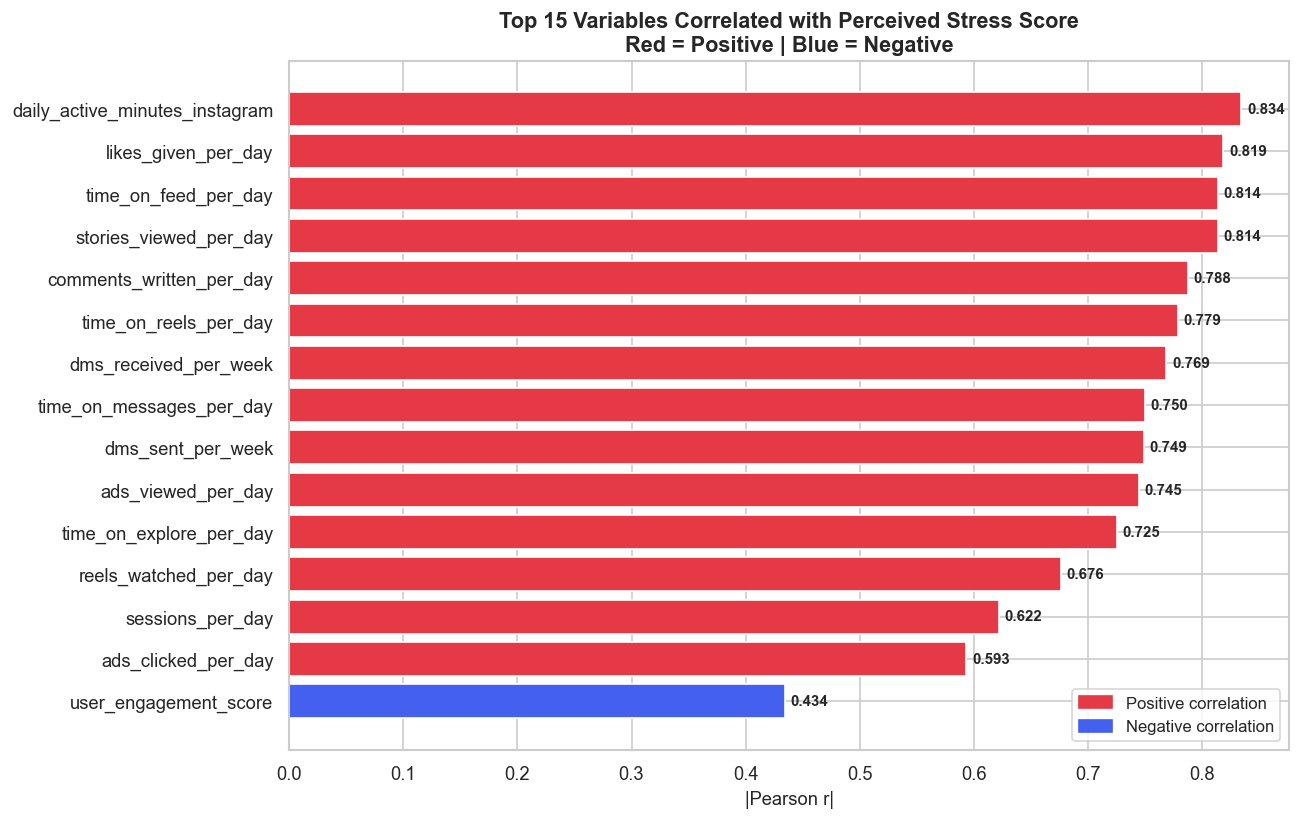


Top 10 Correlations with Stress:
daily_active_minutes_instagram   0.83
likes_given_per_day              0.82
time_on_feed_per_day             0.81
stories_viewed_per_day           0.81
comments_written_per_day         0.79
time_on_reels_per_day            0.78
dms_received_per_week            0.77
time_on_messages_per_day         0.75
dms_sent_per_week                0.75
ads_viewed_per_day               0.74


In [58]:
raw_corr   = df[num_cols].corrwith(df['perceived_stress_score']).drop('perceived_stress_score')
top15      = raw_corr.abs().sort_values(ascending=False).head(15)
bar_colors = ['#E63946' if raw_corr[c] > 0 else '#4361EE' for c in top15.index]

plt.figure(figsize=(11, 7))
bars = plt.barh(top15.index[::-1], top15.values[::-1], color=bar_colors[::-1], edgecolor='white')
for bar in bars:
    plt.text(bar.get_width()+0.005, bar.get_y()+bar.get_height()/2,
             f'{bar.get_width():.3f}', va='center', fontsize=9, fontweight='bold')
plt.xlabel('|Pearson r|')
plt.title('Top 15 Variables Correlated with Perceived Stress Score\nRed = Positive | Blue = Negative',
          fontsize=13, fontweight='bold')
red_p  = mpatches.Patch(color='#E63946', label='Positive correlation')
blue_p = mpatches.Patch(color='#4361EE', label='Negative correlation')
plt.legend(handles=[red_p, blue_p], fontsize=10)
plt.tight_layout(); plt.show()

print('\nTop 10 Correlations with Stress:')
print(raw_corr.abs().sort_values(ascending=False).head(10).to_string())


# Step 8: Outlier Detection
### 8.1 — Box Plots for Key Variables

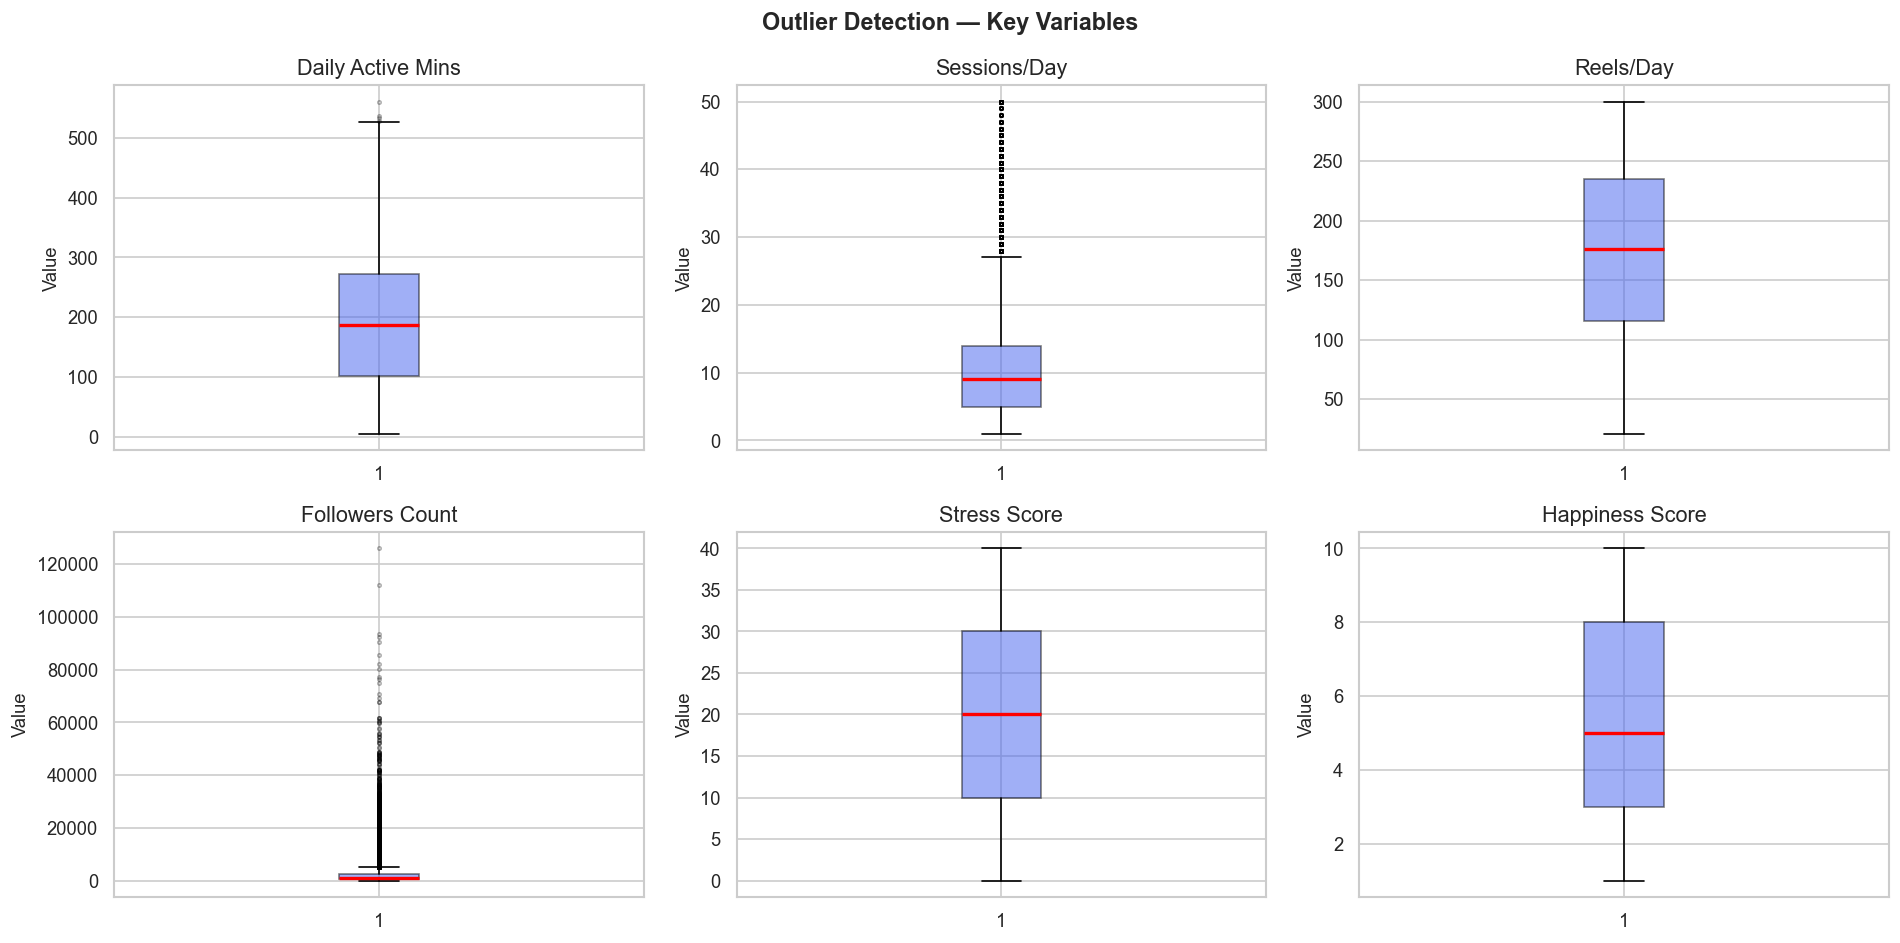

In [59]:
outlier_cols   = ['daily_active_minutes_instagram','sessions_per_day',
                  'reels_watched_per_day','followers_count',
                  'perceived_stress_score','self_reported_happiness']
outlier_labels = ['Daily Active Mins','Sessions/Day','Reels/Day',
                  'Followers Count','Stress Score','Happiness Score']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col, label in zip(axes.flat, outlier_cols, outlier_labels):
    ax.boxplot(df[col], vert=True, patch_artist=True,
               boxprops=dict(facecolor='#4361EE', alpha=0.5),
               medianprops=dict(color='red', lw=2),
               flierprops=dict(marker='o', markersize=2, alpha=0.3, color='grey'))
    ax.set_title(label); ax.set_ylabel('Value')

plt.suptitle('Outlier Detection — Key Variables', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()


### 8.2 — IQR-Based Outlier Count

In [60]:
print(f"{'Column':<45} {'Outliers':>10} {'% of Total':>12}")
print('-' * 68)
for col in outlier_cols:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    n   = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()
    print(f'{col:<45} {n:>10,} {n/len(df)*100:>11.2f}%')


Column                                          Outliers   % of Total
--------------------------------------------------------------------
daily_active_minutes_instagram                         4        0.00%
sessions_per_day                                   4,400        4.40%
reels_watched_per_day                                  0        0.00%
followers_count                                    8,613        8.61%
perceived_stress_score                                 0        0.00%
self_reported_happiness                                0        0.00%


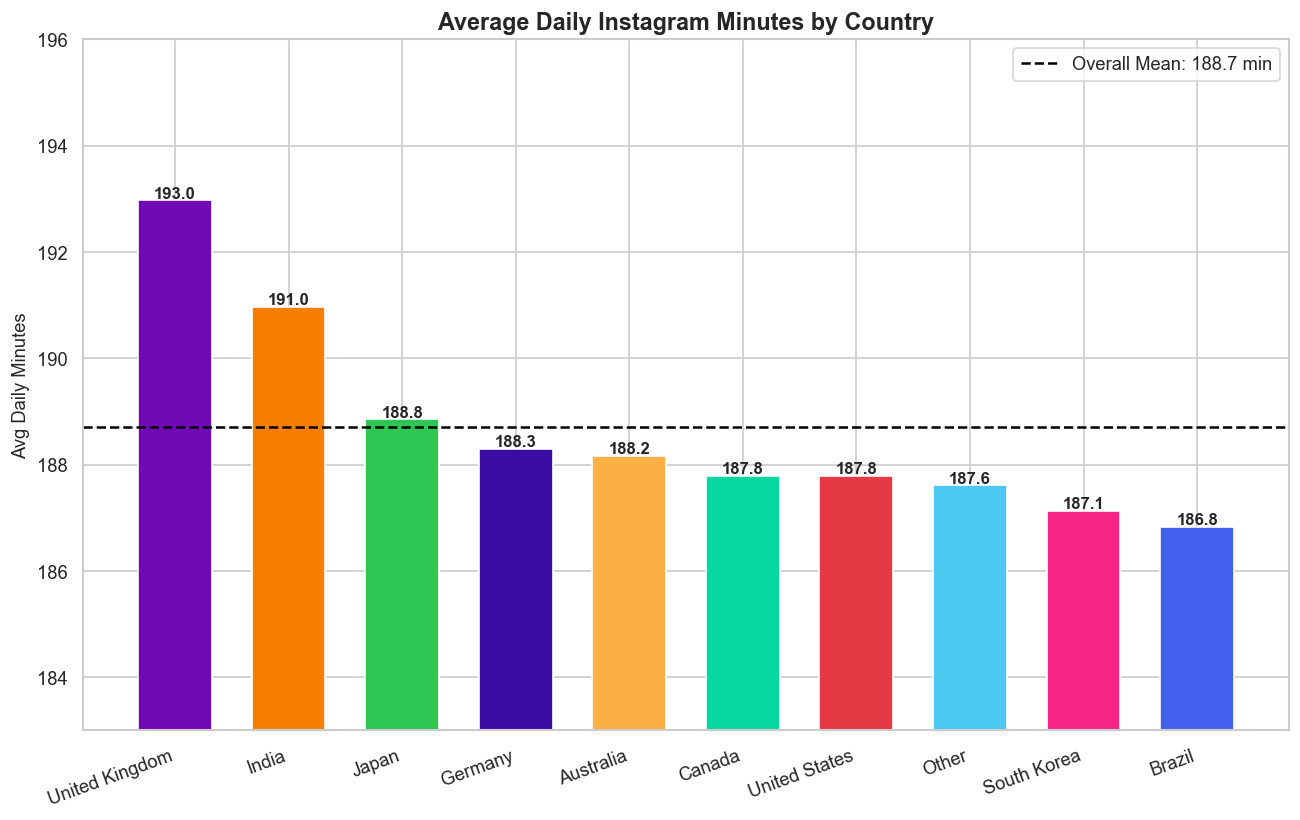

In [70]:
# CHART  — Avg Daily Minutes by Country
fig, ax = plt.subplots(figsize=(11, 7))
avg_mins = df.groupby('country')['daily_active_minutes_instagram'].mean().sort_values(ascending=False)
colors3  = [country_colors[c] for c in avg_mins.index]
bars = ax.bar(avg_mins.index, avg_mins.values, color=colors3, edgecolor='white', width=0.65)
ax.set_ylim(183, 196)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.05,
            f'{bar.get_height():.1f}', ha='center', fontsize=10, fontweight='bold')
ax.axhline(df['daily_active_minutes_instagram'].mean(), color='black', lw=1.5,
           linestyle='--', label=f"Overall Mean: {df['daily_active_minutes_instagram'].mean():.1f} min")
ax.set_xticklabels(avg_mins.index, rotation=20, ha='right')
ax.set_ylabel('Avg Daily Minutes'); ax.legend()
ax.set_title('Average Daily Instagram Minutes by Country', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

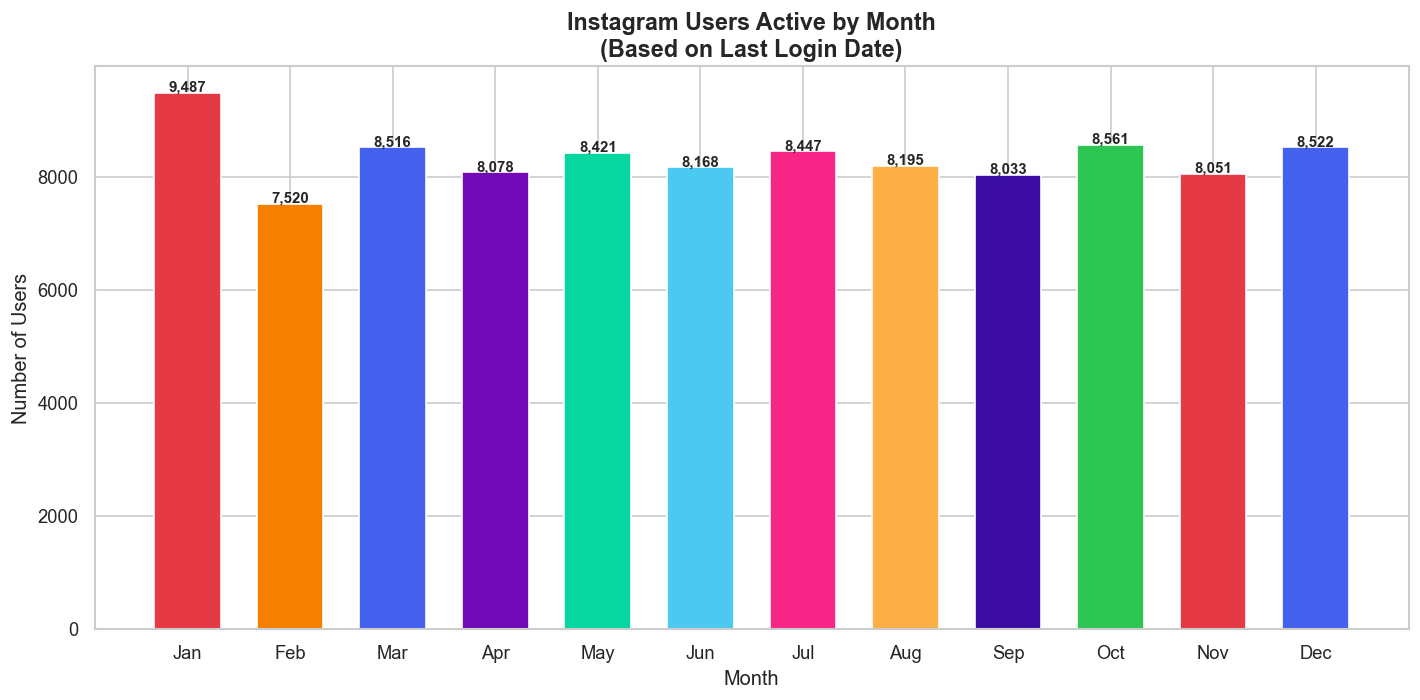

In [72]:
# CHART 5 — Users Active by Month (time-wise)
month_names  = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
month_colors = ['#E63946','#F77F00','#4361EE','#7209B7','#06D6A0','#4CC9F0',
                '#F72585','#FCAF45','#3A0CA3','#2DC653','#E63946','#4361EE']
month_counts = df['login_month'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(month_names, month_counts.values, color=month_colors, edgecolor='white', width=0.65)
for bar in bars:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+30,
            f'{bar.get_height():,}', ha='center', fontsize=9, fontweight='bold')
ax.set_xlabel('Month', fontsize=12); ax.set_ylabel('Number of Users', fontsize=12)
ax.set_title('Instagram Users Active by Month\n(Based on Last Login Date)',
             fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

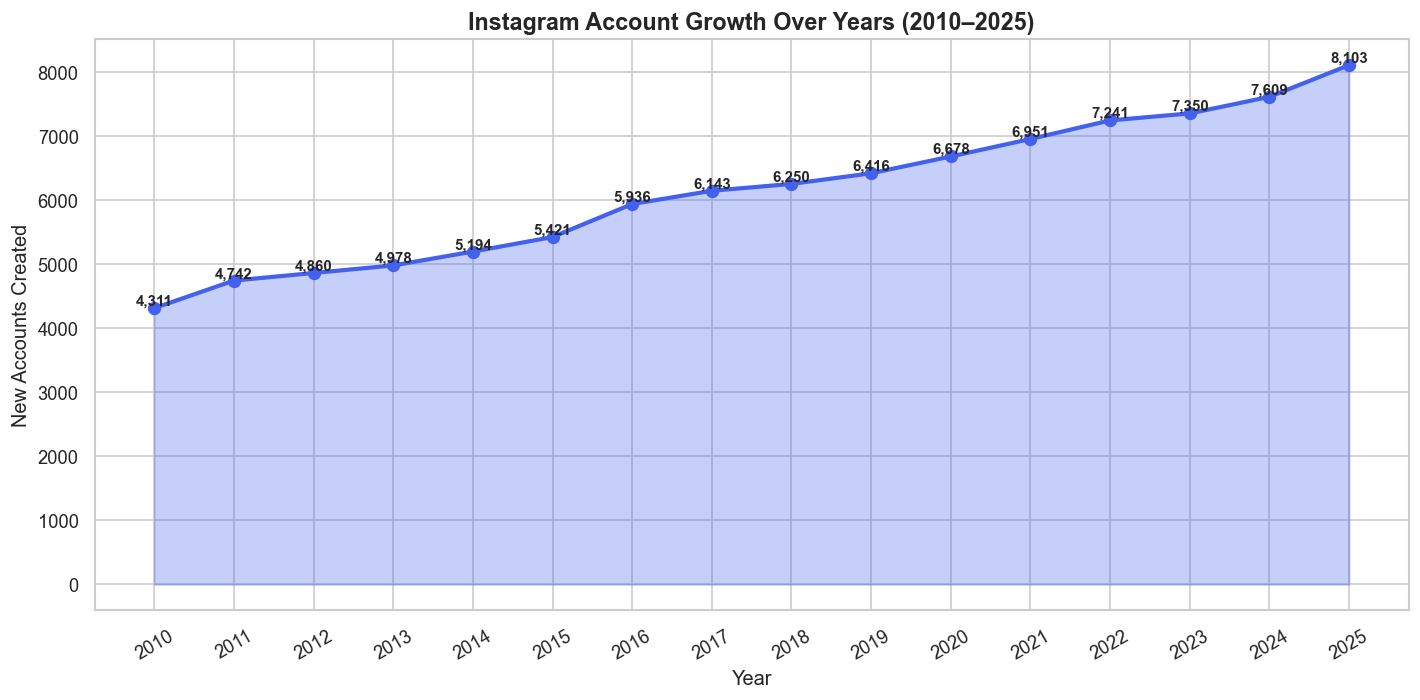

In [73]:
# CHART 6 — Account Growth Over Years (time-wise trend)
year_counts = df[df['account_creation_year'] <= 2025].groupby('account_creation_year').size()

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(year_counts.index, year_counts.values, alpha=0.3, color='#4361EE')
ax.plot(year_counts.index, year_counts.values, color='#4361EE', lw=2.5, marker='o', markersize=7)
for x, y in zip(year_counts.index, year_counts.values):
    ax.text(x, y+50, f'{y:,}', ha='center', fontsize=9, fontweight='bold')
ax.set_xlabel('Year', fontsize=12); ax.set_ylabel('New Accounts Created', fontsize=12)
ax.set_title('Instagram Account Growth Over Years (2010–2025)',
             fontsize=14, fontweight='bold')
ax.set_xticks(year_counts.index); ax.set_xticklabels(year_counts.index, rotation=30)
plt.tight_layout(); plt.show()

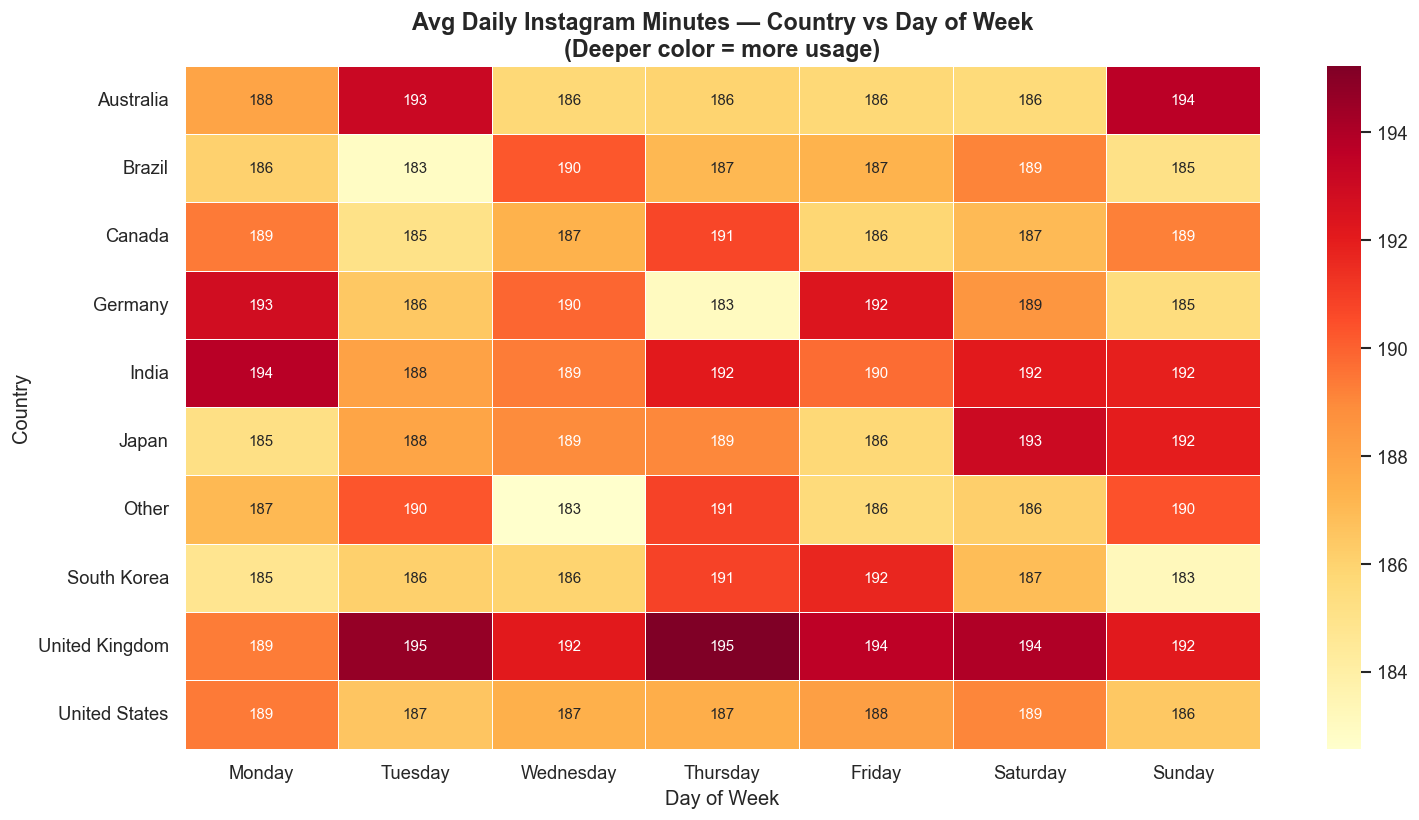

In [74]:
# CHART 7 — Country vs Day of Week Heatmap
day_order2 = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
heat_data  = df.groupby(['country','login_day_name'])['daily_active_minutes_instagram'].mean().unstack()
heat_data  = heat_data[day_order2]

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(heat_data, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax,
            linewidths=0.5, annot_kws={'size':9})
ax.set_title('Avg Daily Instagram Minutes — Country vs Day of Week\n(Deeper color = more usage)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Day of Week', fontsize=12); ax.set_ylabel('Country', fontsize=12)
plt.tight_layout(); plt.show()

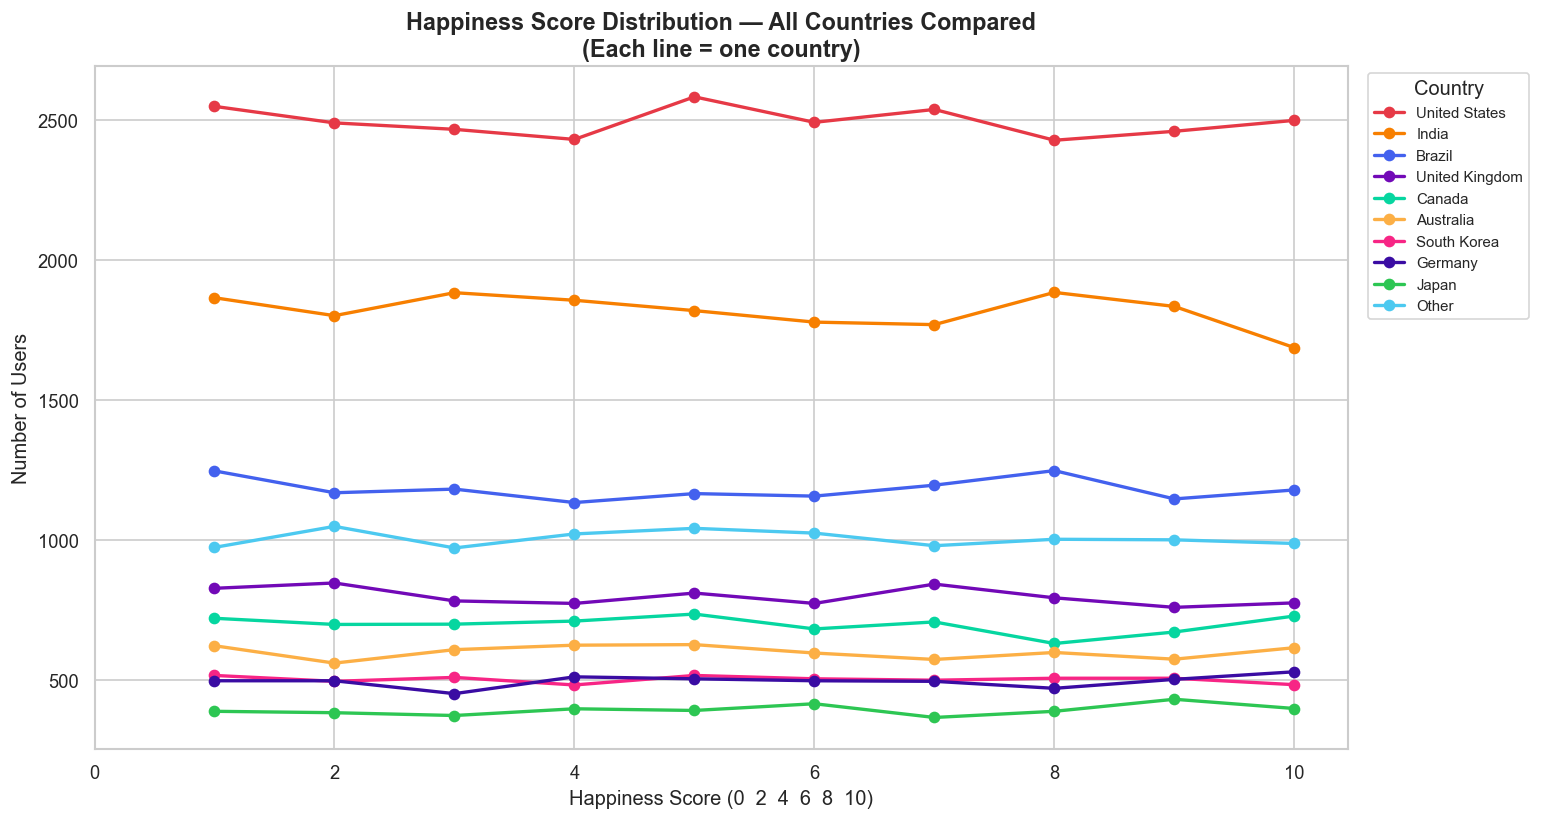

In [75]:
# CHART 8 — Happiness by Country Line Chart (x-axis 0,2,4,6,8,10)
happiness_scores2 = list(range(1, 11))

fig, ax = plt.subplots(figsize=(13, 7))
for country in country_order:
    sub    = df[df['country'] == country]
    counts = sub['self_reported_happiness'].value_counts().sort_index()
    vals   = [counts.get(s, 0) for s in happiness_scores2]
    ax.plot(happiness_scores2, vals, marker='o', lw=2,
            label=country, color=country_colors[country])

ax.set_xticks([0, 2, 4, 6, 8, 10])
ax.set_xlabel('Happiness Score (0  2  4  6  8  10)', fontsize=12)
ax.set_ylabel('Number of Users', fontsize=12)
ax.set_title('Happiness Score Distribution — All Countries Compared\n(Each line = one country)',
             fontsize=14, fontweight='bold')
ax.legend(title='Country', bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout(); plt.show()

# Step 9: Key Insights Summary

In [62]:
high = df[df['perceived_stress_score'] > 20]
low  = df[df['perceived_stress_score'] <= 10]

r1, _ = pearsonr(df['daily_active_minutes_instagram'], df['perceived_stress_score'])
r2, _ = pearsonr(df['daily_active_minutes_instagram'], df['self_reported_happiness'])
r3, _ = pearsonr(df['reels_watched_per_day'],          df['perceived_stress_score'])
r4, _ = pearsonr(df['sessions_per_day'],               df['perceived_stress_score'])

print('=' * 65)
print('             KEY EDA INSIGHTS SUMMARY')
print('=' * 65)

print(f'\n Dataset:')
print(f'   Total users  : {len(df):,}  |  Features: {df.shape[1]}')
print(f'   Missing values: 0  |  Duplicate rows: 0')

print(f'\n Demographics:')
print(f'   Age range   : {df.age.min()} – {df.age.max()}  (mean {df.age.mean():.1f})')
print(f'   Top country : {df.country.value_counts().index[0]} ({df.country.value_counts().iloc[0]:,} users)')
print(f'   Gender      : Male {(df.gender=="Male").mean()*100:.1f}% | Female {(df.gender=="Female").mean()*100:.1f}%')

print(f'\n Instagram Usage:')
print(f'   Avg daily mins   : {df.daily_active_minutes_instagram.mean():.1f}')
print(f'   Avg sessions/day : {df.sessions_per_day.mean():.1f}')
print(f'   Avg reels/day    : {df.reels_watched_per_day.mean():.1f}')

print(f'\n Psychological Scores:')
print(f'   Avg stress    : {df.perceived_stress_score.mean():.2f} / 40')
print(f'   Avg happiness : {df.self_reported_happiness.mean():.2f} / 10')

print(f'\n Key Correlations:')
print(f'   Daily Mins ↔ Stress    : r = {r1:.4f}  → VERY STRONG Positive')
print(f'   Daily Mins ↔ Happiness : r = {r2:.4f}  → MODERATE Negative')
print(f'   Reels/Day  ↔ Stress    : r = {r3:.4f}  → STRONG Positive')
print(f'   Sessions   ↔ Stress    : r = {r4:.4f}  → STRONG Positive')

print(f'\n High vs Low Stress Users:')
print(f'   High stress (>20) : {len(high):,} users | avg {high.daily_active_minutes_instagram.mean():.1f} mins/day')
print(f'   Low  stress (≤10) : {len(low):,} users  | avg {low.daily_active_minutes_instagram.mean():.1f} mins/day')
print(f'   Ratio             : {high.daily_active_minutes_instagram.mean()/low.daily_active_minutes_instagram.mean():.1f}× more usage in high-stress group')

print(f'\n Stress by Usage Bucket:')
bs = df.groupby('usage_bucket', observed=True)['perceived_stress_score'].mean()
for bucket, val in bs.items():
    print(f'   {str(bucket):12} mins/day → avg stress: {val:.1f}')

print('=' * 65)


             KEY EDA INSIGHTS SUMMARY

 Dataset:
   Total users  : 99,999  |  Features: 59
   Missing values: 0  |  Duplicate rows: 0

 Demographics:
   Age range   : 13 – 65  (mean 39.0)
   Top country : United States (24,937 users)
   Gender      : Male 48.4% | Female 47.7%

 Instagram Usage:
   Avg daily mins   : 188.7
   Avg sessions/day : 10.4
   Avg reels/day    : 175.8

 Psychological Scores:
   Avg stress    : 20.00 / 40
   Avg happiness : 5.48 / 10

 Key Correlations:
   Daily Mins ↔ Stress    : r = 0.8343  → VERY STRONG Positive
   Daily Mins ↔ Happiness : r = -0.3729  → MODERATE Negative
   Reels/Day  ↔ Stress    : r = 0.6760  → STRONG Positive
   Sessions   ↔ Stress    : r = 0.6220  → STRONG Positive

 High vs Low Stress Users:
   High stress (>20) : 48,889 users | avg 270.5 mins/day
   Low  stress (≤10) : 26,792 users  | avg 73.5 mins/day
   Ratio             : 3.7× more usage in high-stress group

 Stress by Usage Bucket:
   0–60         mins/day → avg stress: 5.7
   61–1

In [ ]:
df.to_csv('Cleaned_Social_Media_Data.csv', index=False)
print(' Cleaned dataset saved: Cleaned_Social_Media_Data.csv')
print(f'   Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
